# Pump it Up: predicción del estado de puntos de agua en Tanzania

**Competición:** *Data Mining the Water Table* (DrivenData)
**Autor:** Miguel Ángel Castro Torreslanda


---

## Introducción

El objetivo es **predecir el estado de funcionamiento** de ~15.000 puntos de agua de Tanzania,
clasificando cada uno en una de tres categorías:

- **functional** — funciona correctamente
- **functional needs repair** — funciona pero necesita reparación
- **non functional** — no funciona

A lo largo del notebook se da importancia, sobre todo, al **tratamiento de los datos** y **por qué
se toma cada decisión**. Para cada idea se sigue el mismo esquema: se plantea una hipótesis,
la probamos, y anotamos el resultado con el número que lo respalda. Incluimos tanto las ideas que
funcionaron como las que descartamos.

**Resultado principal:** nuestro modelo reproducible alcanza un *accuracy* de **0.8280** en el test
oficial (~puesto #72 de unos 8,700 participantes). Sin embargo, en la última sección documentamos un
experimento adicional en el que exploramos la distancia con los primeros puestos, donde al final logramos un accuracy de **0.8294** con el puesto #12 del leaderboard.

## 1. Los datos

Trabajamos con tres ficheros proporcionados por la competición:

- **`training set values`** — características de los puntos de agua (conjunto de entrenamiento).
- **`training set labels`** — el estado (la etiqueta) de esos puntos.
- **`test set values`** — características de puntos **sin** etiqueta, que hay que predecir.

Las clases están **desbalanceadas**, un hecho que condiciona todo el proyecto:

| Clase | % aproximado |
|---|---|
| functional | 54 % |
| non functional | 38 % |
| functional needs repair | **7 %** |

La clase intermedia (*needs repair*) es minoritaria y, como veremos, es la más difícil de predecir.

## 2. Carga de datos

Cargamos los tres ficheros y unimos las etiquetas con las características del entrenamiento.

Tomamos una decisión desde el inicio: **unir entrenamiento y test en una sola tabla** (transductivo) para calcular
características que **no** dependen de la etiqueta (por ejemplo, cuántos puntos de agua hay cerca
de cada uno) y tener un poco mas de información. Verificamos que las reglas del concurso lo permiten 
(lo que prohíben es usar *datos externos*, no el propio
fichero de test). Las características que **sí** usan la etiqueta se calculan solo con el entrenamiento.

In [ ]:
                                                                                                                            import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors, BallTree
import xgboost as xgb
import matplotlib.pyplot as plt
from pathlib import Path


SEED = 42   # semilla fija para reproducibilidad

# --- Carga de los tres ficheros del concurso ---
# (ajusta los nombres si en tu carpeta difieren)
train_values = pd.read_csv("training_set_values.csv")
train_labels = pd.read_csv("training_set_labels.csv")
test_values  = pd.read_csv("test_set_values.csv")

# Unir características + etiqueta del entrenamiento
train = train_values.merge(train_labels[["id", "status_group"]], on="id")

# Codificar la etiqueta de texto a número (0, 1, 2)
le_y = LabelEncoder()
train["target"] = le_y.fit_transform(train["status_group"])
CLASES = list(le_y.classes_)
print("Clases:", CLASES)

# Distribución de clases
print("\nDistribución de clases en entrenamiento:")
print(train["status_group"].value_counts(normalize=True).round(3))

Clases: ['functional', 'functional needs repair', 'non functional']

Distribución de clases en entrenamiento:
status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: proportion, dtype: float64


In [2]:
# --- Unir train + test en una sola tabla para las características transductivas ---
test_values["target"] = -1                     # -1 marca "sin etiqueta"
full = pd.concat([train.drop(columns="status_group"), test_values], ignore_index=True)
es_train = full["target"] >= 0                 # True si la fila es de entrenamiento
print("Tabla combinada:", full.shape)
print("  - de entrenamiento:", es_train.sum())
print("  - de test:", (~es_train).sum())

Tabla combinada: (74250, 41)
  - de entrenamiento: 59400
  - de test: 14850


## 3. Análisis exploratorio y calidad de los datos

Antes de modelar analizamos los datos con detalle. Encontramos varios problemas típicos de datos
recogidos en campo. Para cada uno explicamos lo que observamos, lo comprobamos con código y anotamos
la decisión que tomamos.

### 3.1 Ceros

Varias columnas numéricas contienen una cantidad sospechosa de ceros. No todas están en la misma
situación:

- **Claramente ausentes:** `construction_year` (un "año 0" es imposible) y `longitude` (Tanzania está
  entre ~29° y ~40° este; un 0 cae en el océano Atlántico).
- **Ambiguas:** `gps_height`, `population` y `amount_tsh`. Aquí un 0 *puede* ser real (un pozo en la
  costa a nivel del mar, un punto sin población alrededor, un pozo seco), pero si la proporción de
  ceros es muy superior a lo esperable, es probable que en muchos casos se usara el 0 como relleno.



In [3]:
cols_cero = ["construction_year", "gps_height", "population", "amount_tsh", "longitude"]

# 1) ¿Cuántos ceros hay en cada columna?
print("Porcentaje de ceros por columna:")
for c in cols_cero:
    print(f"  {c:20s}: {(full[c] == 0).mean():.1%}")

# latitud (0): imposibles, caen en el mar
print("\nPuntos con coordenadas (0, 0):",
      ((full["longitude"] == 0)).sum())

# 2) ¿Coinciden varios ceros en la misma fila?
ceros = full[cols_cero] == 0
print("\nFilas con altura = 0 que también tienen año de construcción = 0:",
      (ceros["gps_height"] & ceros["construction_year"]).sum(), "de", ceros["gps_height"].sum())



Porcentaje de ceros por columna:
  construction_year   : 35.0%
  gps_height          : 34.5%
  population          : 36.1%
  amount_tsh          : 70.1%
  longitude           : 3.1%

Puntos con coordenadas (0, 0): 2269

Filas con altura = 0 que también tienen año de construcción = 0: 24686 de 25649


## 4. Preparación de datos y feature engineering

Transformamos las 40 columnas originales en ~72 features. Explicamos cada familia y por qué
creemos que puede ayudar.

### 4.1 Limpieza y marcas de ausencia
Primero se convirtieron los ceros que creía que eran anómalos en `NaN` y creamos las marcas `*_miss`. Normalizamos el texto y
aplicamos logaritmo a `amount_tsh` y `population` (creo que estaban muy sesgadas y la normalización ayudará a que los extremos no afecten tanto al modelo).

### 4.2 "¿Cómo están los vecinos?"
> **Hipótesis:** los puntos de agua cercanos comparten acuífero, instalador, comité de gestión y
> época de construcción, por lo que **su estado debería parecerse**.

Para cada punto calculamos la fracción de sus **10 vecinos más cercanos** en cada estado
(`nn_rate_0/1/2`), con distancia *haversine* (real sobre la esfera). Como esto usa la etiqueta de los
vecinos, lo calculamos *out-of-fold* (cada trozo del entrenamiento se calcula solo con los demás) para
no "mirar la respuesta"; para el test solo usamos vecinos del entrenamiento.

### 4.3 Target encoding
Para las columnas con muchos valores, sustituimos cada categoría por la tasa histórica de cada estado
en ella, suavizada hacia la media global, también *out-of-fold*.

### 4.4 Geografía sin etiquetas
Distancias al vecino más cercano, densidad de puntos en radios de 1/5/20 km, tamaños de grupo y
desviaciones locales de altura/población.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

.

=== amount_tsh (22201 valores no nulos) ===
  mediana: 250 | percentil 99: 12,000 | máximo: 350,000
  asimetría: 31.7

=== population (47416 valores no nulos) ===
  mediana: 150 | percentil 99: 2,500 | máximo: 30,500
  asimetría: 10.2



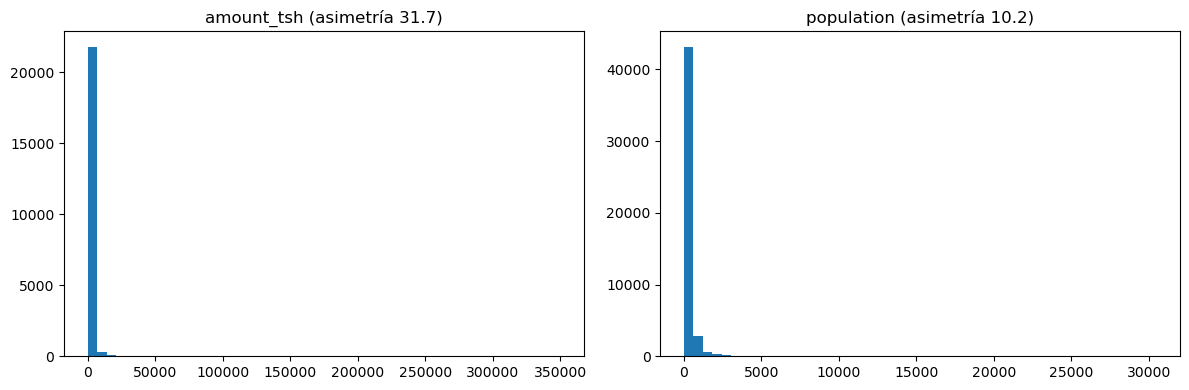

In [4]:
# Sesgo de amount_tsh y population en sus valores originales.
# Excluimos los ceros porque, como vimos en 3.1, en su mayoría son datos ausentes disfrazados.
cols_log = ["amount_tsh", "population"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, cols_log):
    x = full[c].replace(0, np.nan).dropna()

    print(f"=== {c} ({len(x)} valores no nulos) ===")
    print(f"  mediana: {x.median():,.0f} | percentil 99: {x.quantile(0.99):,.0f} | máximo: {x.max():,.0f}")
    print(f"  asimetría: {x.skew():.1f}\n")

    ax.hist(x, bins=50)
    ax.set_title(f"{c} (asimetría {x.skew():.1f})")

plt.tight_layout()
plt.show()

In [5]:
df = full.copy()
df["date_recorded"] = pd.to_datetime(df["date_recorded"], format="mixed", errors="coerce")

# Ceros anómalos
for c in ["construction_year", "gps_height", "population", "amount_tsh", "longitude"]:
    df[c + "_miss"] = (df[c] == 0).astype(int)
    df[c] = df[c].replace(0, np.nan)
df.loc[df["latitude"] > -0.5, "latitude"] = np.nan    # Tanzania empieza en ~-1°: > -0.5 es imposible (placeholder -2e-08)

# Características temporales
df["rec_year"]   = df["date_recorded"].dt.year
df["rec_month"]  = df["date_recorded"].dt.month                                   # mes de la inspección
df["rec_days"]   = (df["date_recorded"] - df["date_recorded"].min()).dt.days   # días desde la primera inspección del dataset
df["antiguedad"] = df["rec_year"] - df["construction_year"]   # años del punto al inspeccionarlo

# Transformaciones de logaritmo para reducir sesgo
df["amount_tsh"] = np.log1p(df["amount_tsh"])
df["population"] = np.log1p(df["population"])

# Normalización de texto
def norm(s):
    return (s.astype(str).str.lower().str.strip()
             .str.replace(r"[^a-z0-9 ]", "", regex=True)
             .str.replace(r"\s+", " ", regex=True).replace({"nan": np.nan, "": np.nan}))
for c in ["funder", "installer", "scheme_name", "wpt_name", "subvillage", "ward", "lga"]:
    df[c] = norm(df[c])

# ============================================================================
# TAMAÑOS DE GRUPO Y DESVIACIONES LOCALES
# Se calculan sobre df, que contiene los 74.250 pozos (entrenamiento + test).
# Considero que es válido hacerlo con todos porque estas características NO usan 
# la etiqueta (transductivo), y así los recuentos y medianas son más completos.
# ============================================================================

# --- Tamaños de grupo (*_n) ---
# Para cada pozo contamos cuántos pozos comparten su mismo valor en la columna.
# Ejemplo: si el instalador de un pozo es "dwe" y "dwe" instaló 21.751 pozos,
# su installer_n vale 21.751. Un instalador con 3 pozos tendrá installer_n = 3.
# Hipótesis: creo que el tamaño dice algo que el nombre solo no dice. Un instalador o
# financiador con miles de pozos suele ser una organización grande (gobierno,
# ONG importante); uno con muy pocos es algo local o puntual. Además, creo que es una forma
# sencilla de representar categorías raras.

for c in ["subvillage", "ward", "lga", "scheme_name", "funder", "installer"]:
    df[c + "_n"] = df.groupby(c)[c].transform("size").fillna(0)

# --- Desviaciones respecto al barrio (*_dev_ward) ---
# Tambien, para cada pozo calculamos cuánto se aparta de lo típico de su barrio (ward):
# valor del pozo - mediana de ese valor en su barrio.
# Ejemplo: un pozo a 1.500 m en un barrio cuya mediana es 1.200 m -> +300.
# Hipótesis: el valor absoluto dice poco (1.500 m es normal en unas zonas y raro
# en otras); lo informativo puede ser que un pozo esté en una situación distinta
# a la de sus vecinos (más alto que el resto, más antiguo, con más población).
# Usamos la mediana y no la media porque no se ve arrastrada por valores extremos.
# Nota: population ya pasó por el log, así que su desviación mide diferencias
# relativas (cuántas veces más población que la mediana del barrio), no absolutas.

for c in ["gps_height", "population", "construction_year"]:
    df[f"{c}_dev_ward"] = df[c] - df.groupby("ward")[c].transform("median")

In [6]:
# ============================================================================
# CARACTERÍSTICAS GEOGRÁFICAS: DISTANCIAS Y DENSIDADES
# Dos familias que no usan la etiqueta:
#   - Aislamiento (nn_dist_*): a qué distancia están los vecinos más cercanos.
#   - Densidad (dens_*km): cuántos pozos hay alrededor dentro de un radio definido.
# Hipótesis: un pozo muy aislado probablemente recibe menos visitas de
# mantenimiento, y una zona con muchos pozos suele tener más presencia.
# ============================================================================

# --- 1. Quedarnos solo con los pozos que tienen coordenadas ---
# La búsqueda de vecinos no funciona con valores vacíos, así que excluimos los
# 1.812 pozos cuya coordenada era un placeholder (y que convertimos en NaN).
# notna() = "no está vacío"; all(axis=1) = "ambas columnas de esa fila".


geo_ok = df[["longitude", "latitude"]].notna().all(axis=1)

# Posiciones (número de fila) de los pozos válidos. Las usaremos al final para escribir cada resultado en la fila correcta de df.

pos = np.where(geo_ok)[0]

# Coordenadas de los pozos válidos, en el orden [latitud, longitud] y convertida a radianes. 
# Como la latitud y la longitud vienen en grados, y la distancia haversine de scikit-learn exige que esos ángulos sean radianes, tenemos que convertirlos con np.radians().

C = np.radians(df.loc[geo_ok, ["latitude", "longitude"]].values)

# Para esos mismos pozos: cuáles son de entrenamiento y cuál es su etiqueta.
# No se usan en esta celda; los preparamos para la siguiente (nn_rate), que sí
# necesita las etiquetas de los vecinos.

tr_geo = es_train.values[pos]
y_geo  = df["target"].values[pos]

# --- 2. Función auxiliar para guardar resultados ---
# Crea una nueva columna y rellena solo las filas de los pozos con
# coordenadas. Así, los pozos sin coordenadas quedan con NaN en estas
# características (XGBoost puede manejarlos).
# get_loc(col) devuelve el número de la columna, que es lo que necesita iloc.

def set_pos(col, val):
    df[col] = np.nan
    df.iloc[pos, df.columns.get_loc(col)] = val

# --- 3. Aislamiento: distancia a los vecinos más cercanos ---
# Buscamos los 21 pozos más cercanos a cada uno. Son 21 y no 20 porque el más
# cercano a cada pozo es él mismo (a distancia 0): así nos quedan él + 20 vecinos.
# metric="haversine": distancia sobre la superficie de una esfera (la Tierra),
# no en línea recta como si el mapa fuera plano.
# n_jobs=-1: usa todos los recursos para ir más rápido.

nn_all = NearestNeighbors(n_neighbors=21, metric="haversine", n_jobs=-1).fit(C)

# kneighbors devuelve dos tablas (una fila por pozo, 21 columnas ordenadas de
# más cerca a más lejos): las distancias y los índices de los vecinos.
# Aquí solo necesitamos las distancias; los índices se descartan con "_".

d_all, _ = nn_all.kneighbors(C)

# La distancia haversine sale en radianes (un ángulo). Multiplicando por el radio
# de la Tierra (6.371 km) la convertimos en kilómetros: arco = ángulo × radio.
# La columna 0 es el propio pozo, por eso empezamos en la columna 1.

set_pos("nn_dist_1",  d_all[:, 1] * 6371)
set_pos("nn_dist_5",  d_all[:, 1:6].mean(1) * 6371)
set_pos("nn_dist_20", d_all[:, 1:].mean(1) * 6371)

# --- 4. Densidad: cuántos pozos hay dentro de un radio ---
# BallTree organiza los puntos en "círculos" para poder buscar rápido.
# Lo construimos una sola vez y lo reutilizamos para los tres radios.
# (Usamos BallTree porque admite la distancia haversine; KDTree no.)

tree = BallTree(C, metric="haversine")
for km in [1, 5, 20]:
    set_pos(f"dens_{km}km", tree.query_radius(C, r=km/6371, count_only=True) - 1)

# ¿Por qué distancias Y densidades, y a varias escalas?
# Se complementan: en zonas remotas casi todos los pozos tienen 0 vecinos en 1 km
# (la densidad no distingue nada) pero la distancia sí; en zonas urbanas pasa al
# revés. Creo que las tres escalas (1, 5, 20 km) captan desde el entorno inmediato hasta la región.

In [7]:
# ============================================================================
# TASAS DE ESTADO DE LOS VECINOS (nn_rate_0, nn_rate_1, nn_rate_2)
# Para cada pozo calculamos qué fracción de sus 10 vecinos más cercanos está en
# cada estado:
#   nn_rate_0 = % de vecinos "functional"
#   nn_rate_1 = % de vecinos "functional needs repair"
#   nn_rate_2 = % de vecinos "non functional"
# (el orden 0/1/2 es el que asignó LabelEncoder, y las tres deben sumar 1 en cada pozo).
#
# Hipótesis: los pozos cercanos normalmente deberian compartir acuífero, instalador, comité de gestión
# y época de construcción, así que su estado debería parecerse. Si a un pozo lo
# rodean pozos rotos, es probable que él también lo esté.
#
# A diferencia de las distancias y densidades, estas características SÍ usan la
# etiqueta (el estado de los vecinos). Por eso hay que tener dos precauciones:
#   1) Los vecinos solo pueden ser pozos de ENTRENAMIENTO (los de test no tienen
#      etiqueta que consultar).
#   2) Un pozo de entrenamiento no puede usar su propia etiqueta, ni directa ni
#      indirectamente. Para eso lo calculamos out-of-fold.
# ============================================================================

K = 10

# Coordenadas y etiquetas de los pozos de ENTRENAMIENTO con coordenadas válidas.
# (C, tr_geo e y_geo vienen de la celda anterior.)
# Estos son los únicos pozos que pueden actuar como "vecinos de referencia".

Ctr, ytr_g = C[tr_geo], y_geo[tr_geo]

# --- Función que calcula las tasas ---
# fitC, fity: coordenadas y etiquetas de los pozos de referencia (entre los que se busca).
# qC: coordenadas de los pozos para los que queremos calcular las tasas.

def rates(fitC, fity, qC):
    nn = NearestNeighbors(n_neighbors=K, metric="haversine", n_jobs=-1).fit(fitC)  # Preparamos el buscador con los pozos de referencia
    # Para cada pozo de qC, buscamos sus 10 vecinos más cercanos entre los de referencia.
    # Aquí sí necesitamos saber QUIÉNES son (índices), no las distancias -> "_".
    # Nota: pedimos 10 y no 11 porque, tal como está montado, el pozo que se consulta nunca está entre los de referencia (ni los de test, ni los del trozo que se calcula), así que no se encuentra a sí mismo.
    _, idx = nn.kneighbors(qC)
    lab = fity[idx]      # lab es una tabla con una fila por pozo y 10 columnas: la etiqueta de cada vecino.
    
    # Para cada clase (0, 1, 2), (lab == c) marca con True los vecinos de esa clase y .mean(1) calcula la fracción por fila. 
    # np.stack junta las tres fracciones en una tabla de 3 columnas

    return np.stack([(lab == c).mean(1) for c in range(3)], axis=1)

# --- Tabla donde guardaremos los resultados ---
# Una fila por cada pozo con coordenadas (train y test) y 3 columnas (una por clase).

R = np.full((len(pos), 3), np.nan)

# --- Pozos de TEST ---
# Sus vecinos se buscan entre TODOS los pozos de entrenamiento.
# ~tr_geo invierte la máscara: selecciona los pozos que NO son de entrenamiento.

R[~tr_geo] = rates(Ctr, ytr_g, C[~tr_geo])                 # test: vecinos de train

# --- Pozos de ENTRENAMIENTO (out-of-fold) ---
# ¿Por qué no calcular las tasas de un pozo de entrenamiento usando directamente
# todos los demás pozos de entrenamiento?
# Porque el pozo también está en esa lista: al buscar sus 10 vecinos más cercanos,
# el primero sería él mismo (a distancia 0), y su propia etiqueta pasaría a formar
# parte de la característica. 
#
# Solución (out-of-fold): dividimos el entrenamiento en 5 trozos. Para los pozos de
# cada trozo, buscamos los vecinos solo entre los otros 4. Así ningún pozo puede
# encontrarse a sí mismo, y su tasa se calcula igual que la de un pozo de test.
#
# ¿No bastaría con descartar al propio pozo de la lista? En gran parte sí. Pero se prefirió
# los trozos por dos motivos: es el mismo que usamos en el target
# encoding, y también cubre los pozos registrados dos veces con la misma ubicación,
# que quitando solo "al propio pozo" seguirían aportando la respuesta.
#
# Elegimos 5 trozos como equilibrio: cada pozo busca vecinos entre el 80 % del
# entrenamiento. Con más trozos se parecería más al test (que usa el 100 %),
# pero el cálculo sería más lento.

tr_idx = np.where(tr_geo)[0]
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Ctr, ytr_g):
    R[tr_idx[b]] = rates(Ctr[a], ytr_g[a], Ctr[b])         # train: out-of-fold

# --- Guardar las tasas de TODOS los pozos (train y test) en df ---
# Estas columnas acaban en X_train (para entrenar el modelo) y en X_test (para predecir).
for k in range(3):
    set_pos(f"nn_rate_{k}", R[:, k])

In [8]:
# ============================================================================
# TARGET ENCODING SUAVIZADO Y OUT-OF-FOLD
#
# Columnas como funder, installer, ward o subvillage tienen miles de
# valores distintos (nombres de financiadores, instaladores, barrios...). 
#
# Idea: sustituir cada nombre por la proporción histórica de cada estado entre los pozos de esa categoría. Por ejemplo, si de los
# pozos instalados por "roman" el 60 % funciona, el 5 % necesita reparación y el
# 35 % no funciona, esos tres números sustituyen al nombre "roman".
# Así creamos tres columnas por cada columna original:
#   <col>_te0 = % functional, <col>_te1 = % needs repair, <col>_te2 = % non functional
#
# Hipótesis: quién financia, quién instala y dónde está el pozo influyen en su
# mantenimiento; la historia de cada categoría resume esa influencia en números.
#
# Igual que las tasas de vecindad, esto si usa la etiqueta, así que necesita dos cuidados:
#   1) Suavizado: no fiarnos de categorías con muy pocos pozos.
#   2) Out-of-fold: que ningún pozo de entrenamiento use su propia etiqueta.
# ============================================================================


def te_col(col, m=20):
    out = np.full((len(df), 3), np.nan)
    ytr = df.loc[es_train, "target"]; ktr = df.loc[es_train, col]
    
    # "prior": la proporción de cada clase en todo el entrenamiento (~54 %, ~7 %, ~38 %).
    # Es el valor de referencia hacia el que "encogemos" las categorías con pocos datos,
    # y el que reciben las categorías que nunca hemos visto.

    prior = np.array([(ytr == k).mean() for k in range(3)])

    # --- SUAVIZADO: la fórmula ---
    # Para cada categoría y clase:
    #
    #   valor = (media_categoría * n_pozos + prior * m) / (n_pozos + m)
    #
    # Es una media ponderada entre lo que dice la categoría y lo que dice el conjunto.
    # m = 20 funciona como si añadiéramos 20 pozos "imaginarios" con la proporción global.
    #   - Categoría con 2 pozos, ambos rotos (100 %): (1*2 + 0.38*20) / 22 ≈ 0.44
    #     -> no nos fiamos de 2 pozos; el valor se acerca al 38 % global.
    #   - Categoría con 1.000 pozos, 60 % rotos: (0.6*1000 + 0.38*20) / 1020 ≈ 0.596
    #     -> con tantos datos, apenas cambia.
    # Sin suavizado, una categoría con un único pozo roto valdría 100 %.
    # El valor m = 20 es una elección que me pareció razonable, y no está realmente optimizada ni justificada pero creo que funcionó.


    for k in range(3):
        st = (ytr == k).astype(float).groupby(ktr).agg(["mean", "count"])
        sm = (st["mean"]*st["count"] + prior[k]*m) / (st["count"] + m)
        out[~es_train.values, k] = df.loc[~es_train, col].map(sm).fillna(prior[k]).values
    
    # --- Pozos de ENTRENAMIENTO: out-of-fold ---
    # Si calculáramos la proporción de una categoría con todos los pozos de
    # entrenamiento, cada pozo aportaría su propia etiqueta al valor que recibe.
    # El caso extremo: una categoría con un solo pozo recibiría exactamente su propia
    # etiqueta. El modelo aprendería a fiarse de esta columna, y en el test esa ayuda
    # desaparecería.
    # Solución: igual que con las tasas de vecindad, dividimos el entrenamiento en
    # 5 trozos y calculamos los valores de cada trozo usando solo los otros 4.

    # Posiciones de los pozos de entrenamiento dentro de df (el "traductor", como tr_idx).
    # StratifiedKFold devuelve posiciones relativas a ktr/ytr, y out tiene una fila por pozo de df.
    
    tr_ix = np.where(es_train)[0]
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(ktr, ytr):
        for k in range(3):
            st = (ytr.iloc[a] == k).astype(float).groupby(ktr.iloc[a]).agg(["mean", "count"])
            sm = (st["mean"]*st["count"] + prior[k]*m) / (st["count"] + m)
            out[tr_ix[b], k] = ktr.iloc[b].map(sm).fillna(prior[k]).values
    return out

for c in ["funder", "installer", "ward", "subvillage", "lga", "scheme_name"]:
    te = te_col(c)
    for k in range(3):
        df[f"{c}_te{k}"] = te[:, k]

In [9]:
# ============================================================================
# CODIFICACIÓN FINAL Y SEPARACIÓN TRAIN / TEST
# Hasta aquí df tiene las columnas originales más todas las que hemos creado.
# En esta celda:
#   1) quitamos las columnas que no queremos usar
#   2) convertimos el texto que queda en números,
#   3) volvemos a separar entrenamiento y test.
# ============================================================================

# --- 1. Columnas que eliminamos ---
# - id: solo es un identificador, no dice nada del pozo.
# - target: es la etiqueta; no puede estar entre las características.
# - recorded_by, num_private: no aportan información (la primera es constante y
#   la segunda es 0 en casi todas las filas).
# - date_recorded: ya extrajimos de ella rec_year, rec_month, rec_days y antiguedad.
# - quantity_group, payment_type, extraction_type_group, waterpoint_type_group,
#   source_type, region_code: son versiones repetidas o resumidas de otras columnas que sí conservamos.
# - wpt_name, subvillage, scheme_name: texto con demasiados valores distintos para usarlo tal cual; su información ya está en los tamaños de grupo (*_n) y en el target encoding (*_te).


DROP = ["id", "target", "recorded_by", "date_recorded", "num_private",
        "quantity_group", "payment_type", "extraction_type_group",
        "waterpoint_type_group", "source_type", "region_code",
        "wpt_name", "subvillage", "scheme_name"]

# Guardamos aparte lo que necesitaremos más adelante:
# - ids_test: los identificadores de los pozos de test, para el fichero de envío.
# - y_full: las etiquetas (0, 1, 2) de los 59.400 pozos de entrenamiento.
ids_test = full.loc[~es_train, "id"].values
y_full   = full.loc[es_train, "target"].values

X = df.drop(columns=[c for c in DROP if c in df.columns])

# --- 2a. Columnas de identidad: nos quedamos con las 40 categorías más frecuentes ---

# funder, installer, ward y lga siguen teniendo cientos o miles de valores. Su
# información detallada ya la recogen el target encoding y los tamaños de grupo.
# Aquí conservamos solo las 40 categorías más frecuentes de cada una (las que tienen
# suficientes pozos para que el modelo aprenda algo de ellas) y agrupamos el resto
# en "otros".
# Nota: los valores vacíos también acaban en "otros".
for c in ["funder", "installer", "ward", "lga"]:
    top = X[c].value_counts().nlargest(40).index              # las 40 más frecuentes
    X[c] = X[c].where(X[c].isin(top), "otros").fillna("desconocido")

# --- 2b. Texto -> números ---
# XGBoost necesita números. LabelEncoder asigna un número a cada categoría
# (por ejemplo, "gravity" -> 3). A los árboles no les afecta que esos números no
# tengan un orden real, porque dividen por categorías. Para la red neuronal, en
# cambio, convertiremos estas columnas en one-hot más adelante.
# astype(str) es necesario porque algunas columnas mezclan True/False con vacíos.

for c in X.select_dtypes(include=["object", "bool"]).columns:
    X[c] = LabelEncoder().fit_transform(X[c].astype(str))

# --- 3. Volvemos a separar entrenamiento y test con la máscara es_train ---
X_train, X_test = X[es_train.values], X[~es_train.values]
print("X_train:", X_train.shape, "| X_test:", X_test.shape) 

X_train: (59400, 72) | X_test: (14850, 72)


## 5. Cómo medimos si algo funciona (nuestra regla de oro)

Antes de probar modelos definimos **cómo íbamos a medir**, porque es lo que evita autoengañarse.

Separamos un 20 % del entrenamiento como *holdout* (11.880 puntos que el modelo no ve al entrenar) y
medimos sobre él. Pero toda medición tiene **ruido**. Con 11.880 puntos y precisión ~80 %, el error
estándar del *accuracy* es:

$$SE = \sqrt{\frac{p(1-p)}{n}} = \sqrt{\frac{0.80 \cdot 0.20}{11880}} \approx 0.0036$$

> **Regla que aplicamos en todo el proyecto:** una diferencia menor de ~0.007 (dos errores estándar)
> no la consideramos una mejora real, sino ruido de muestreo. Esto nos hizo descartar varias ideas
> que "parecían" mejorar pero solo tenían suerte con esta partición concreta.

In [10]:
# ============================================================================
# HOLDOUT: RESERVAMOS UN 20 % DEL ENTRENAMIENTO PARA MEDIR
# El modelo se entrena con el 80 % (X_tr, y_tr) y se evalúa con el 20 % restante
# (X_ho, y_ho), que no ha visto durante el entrenamiento. Así estimamos cómo se
# comportará con pozos nuevos.
# ============================================================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# test_size=0.2     -> 20 % para evaluar (11.880 pozos).
# random_state=SEED -> la partición es siempre la misma, así los experimentos son comparables.
# stratify=y_full   -> el holdout mantiene la misma proporción de clases (54/38/7) que el total.
X_tr, X_ho, y_tr, y_ho = train_test_split(
    X_train, y_full, test_size=0.2, random_state=SEED, stratify=y_full)

n = len(y_ho)
print(f"Holdout: {n} filas")

Holdout: 11880 filas


## 6. Elección de modelo

**¿Por qué XGBoost como modelo principal?** Nuestros datos son tabulares y heterogéneos (números,
categorías, geografía). En este tipo de datos, los modelos de árboles (*gradient boosting*) suelen
superar a las redes neuronales (Grinsztajn et al., 2022). Además, XGBoost gestiona por sí mismo los
valores ausentes y es indiferente a la escala de las variables.

**¿Por qué no una red neuronal sola?** La probamos: daba ~0.80, por debajo de XGBoost (~0.816).

**¿Por qué entonces mezclarla (blend)?** Aunque la red es más débil, **se equivoca en filas distintas**
que XGBoost (correlación de errores 0.71). Sin embargo, creo que cuando dos modelos fallan en sitios diferentes, combinarlos
como ensable puede mejorar el conjunto:

| Modelo | Accuracy (holdout) |
|---|---|
| XGBoost solo | 0.8160 |
| Red neuronal (MLP) sola | 0.8002 |
| **Blend 80 % XGB + 20 % MLP** | **0.8189** |

> **Conclusión:** la red neuronal, siendo el modelo más débil, fue el único que aportó al blend,
> porque es diversa. En una mezcla no importa solo cómo de bueno es cada modelo, sino cuánto se
> diferencia de los demás.

Los hiperparámetros de XGBoost se ajustaron con **Optuna** (búsqueda automática con validación cruzada).

In [11]:
# ============================================================================
# AJUSTE DE HIPERPARÁMETROS CON OPTUNA  —  SOLO COMO REFERENCIA, NO SE EJECUTA
#
# Esta es la búsqueda que hicimos para encontrar los hiperparámetros de XGBoost
# que usa todo el notebook (PARAMS_XGB). Tarda unos 20–30 minutos, así que está
# desactivada: con EJECUTAR_OPTUNA = False la celda no hace nada.
# Para reproducirla: instala optuna (pip install optuna) y cambia el interruptor a True.
# ============================================================================
EJECUTAR_OPTUNA = False

if EJECUTAR_OPTUNA:
    import optuna
    from sklearn.model_selection import cross_val_score
    optuna.logging.set_verbosity(optuna.logging.WARNING)   # solo mostrar avisos importantes

    # --- Qué hace Optuna ---
    # Prueba combinaciones de hiperparámetros y se queda con la que mejor valida.

    def objetivo(trial):
        # Rango de valores en el que Optuna puede buscar cada hiperparámetro.
        # log=True: explora en escala logarítmica, útil cuando el valor puede variar
        # varios órdenes de magnitud (0.1, 1, 10...).
        p = dict(
            max_depth        = trial.suggest_int("max_depth", 8, 16),
            min_child_weight = trial.suggest_int("min_child_weight", 1, 10),
            subsample        = trial.suggest_float("subsample", 0.6, 1),
            colsample_bytree = trial.suggest_float("colsample_bytree", 0.4, 1),
            gamma            = trial.suggest_float("gamma", 0, 0.5),
            reg_lambda       = trial.suggest_float("reg_lambda", 0.1, 10, log=True),
            reg_alpha        = trial.suggest_float("reg_alpha", 0.01, 5, log=True),
        )
        # Para que cada prueba sea rápida, evaluamos con 400 árboles y learning_rate=0.1
        # (el modelo final usa 1500 árboles y 0.04). max_bin=128 también acelera el entrenamiento.
        m = xgb.XGBClassifier(**p, n_estimators=400, learning_rate=0.1,
                              tree_method="hist", max_bin=128,
                              objective="multi:softmax", num_class=3,
                              random_state=SEED, n_jobs=8)
        # Cada combinación se evalúa con validación cruzada de 3 trozos sobre el
        # entrenamiento (sin fe_dist ni fe_days, que se añadieron después), y se
        # devuelve el accuracy medio. Optuna intenta maximizarlo.
        return cross_val_score(m, X_train, y_full,
                               cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                               scoring="accuracy", n_jobs=1).mean()

    # direction="maximize": buscamos el mayor accuracy.
    # TPESampler(seed=SEED): fija la semilla del buscador para que la búsqueda sea reproducible.
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=50, show_progress_bar=True)

    print(f"Mejor accuracy en validación cruzada: {study.best_value:.4f}")
    print("Mejores hiperparámetros:", study.best_params)

# --- Resultado que obtuvimos (el que se usa en PARAMS_XGB) ---
# Mejor accuracy en validación cruzada: 0.8144
# {'max_depth': 15, 'min_child_weight': 9, 'subsample': 0.9546224293994223,
#  'colsample_bytree': 0.760539054190109, 'gamma': 0.223944661093914,
#  'reg_lambda': 0.7091907609838727, 'reg_alpha': 0.054068632150324515}
#
# --- Lo que aprendimos al intentar ir más allá ---
# Más adelante ampliamos la búsqueda a 250 pruebas y el resultado en el test EMPEORÓ
# (de 0.8253 a 0.8214). Dos motivos:
#   1) Las pruebas se evaluaban con 400 árboles y learning_rate=0.1, pero el modelo
#      final usa 1500 y 0.04. La mejor profundidad depende de ese régimen, y la
#      configuración "ganadora" (profundidad 16, el máximo del rango) resultó
#      excesiva en el modelo final.
#   2) Tras 250 pruebas contra la misma validación, la combinación ganadora es cada
#      vez más la que tuvo suerte con esas particiones concretas, y no la mejor de verdad.
# Por eso nos quedamos con el resultado de las primeras 50 pruebas.

In [12]:
# ============================================================================
# DEFINICIÓN DE LOS MODELOS
# Definimos aquí, una sola vez, cómo se construye cada modelo. Así usamos
# exactamente la misma configuración en los experimentos y en el envío final.
# ============================================================================
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# --- XGBoost ---
# Hiperparámetros encontrados con Optuna (50 pruebas con validación cruzada de 3 trozos).
# Los copiamos con todos sus decimales: redondearlos cambiaría ligeramente el modelo
# y no reproduciríamos exactamente el resultado del concurso.
#   max_depth        -> profundidad máxima de cada árbol (15: árboles profundos que
#                       captan interacciones complejas entre variables).
#   min_child_weight -> "cantidad" mínima de datos en una hoja; evita hojas con muy pocos pozos.
#   subsample        -> cada árbol se entrena con ~95 % de las filas, elegidas al azar.
#   colsample_bytree -> cada árbol usa ~76 % de las columnas, elegidas al azar.
#   gamma            -> mejora mínima exigida para hacer una división (frena divisiones inútiles).
#   reg_lambda / reg_alpha -> regularización L2 y L1: penalizan hojas con valores extremos.
PARAMS_XGB = dict(max_depth=15, min_child_weight=9,
                  subsample=0.9546224293994223, colsample_bytree=0.760539054190109,
                  gamma=0.223944661093914, reg_lambda=0.7091907609838727,
                  reg_alpha=0.054068632150324515)

def make_xgb(seed, **extra):
    # n_estimators=1500 con learning_rate=0.04: muchos pasos pequeños, que tengo entendido suele servir para generalizar mejor que pocos pasos grandes.
    # tree_method="hist": agrupa los valores de cada variable en intervalos para entrenar más rápido.
    # objective="multi:softprob": 3 clases, devolviendo probabilidades (las necesitamos para mezclar modelos en el blend).
    # **extra: permite cambiar algún parámetro puntual en un experimento concreto.
    return xgb.XGBClassifier(**PARAMS_XGB, n_estimators=1500, learning_rate=0.04,
                             tree_method="hist", objective="multi:softprob",
                             num_class=3, random_state=seed, n_jobs=-1, **extra)

# --- Red neuronal (MLP) ---
# A diferencia de los árboles, la red trabaja con magnitudes (multiplica cada valor por un peso y suma), así que necesitamos:
#   - columnas numéricas sin vacíos y en la misma escala;
#   - columnas categóricas en one-hot (una columna 0/1 por categoría), porque los números de LabelEncoder (0, 1, 2...) sugieren que hay un orden y no lo hay.
#
# En este punto todas las columnas de X_train ya son números, así que tuve que decidir de manera no tan ortodoxa, cuáles eran categorías en un inicio.
# Para esto use regla sencilla aunque no 100% cierta: pocos valores distintos (<= 45) y todos enteros -> categórica.
# Las marcas *_miss (0/1) se tratan como numéricas, porque pasarlas a one-hot crearía dos columnas que dicen lo mismo.
#
# Limitación: como acabo de mencionar, la regla inventada no es la opción más precisa. Algunas columnas con orden natural,
# como rec_year o rec_month, cumplen la regla y acaban como categóricas. Lo ideal habría
# sido indicar a mano qué columnas eran categorías antes del LabelEncoder. Lo dejamos así
# porque es la configuración con la que entrenamos los modelos de los envíos (0.8280 y
# 0.8294): cambiarla obligaría a rehacer todo el entrenamiento y los resultados ya no se
# reproducirían exactamente y el tiempo no me lo permitió. SIn embargo, creo que con los pocos valores, el one-hot de esas columnas debería de funcionar bien igualmente, 
# así que el impacto esperado, en todo caso de que hubiera, debería ser pequeño.

cat_nn = [c for c in X_train.columns
          if X_train[c].dropna().nunique() <= 45
          and (X_train[c].dropna() == X_train[c].dropna().astype(int)).all()
          and not c.endswith("_miss")]
num_nn = [c for c in X_train.columns if c not in cat_nn]
print(f"Red neuronal: {len(cat_nn)} columnas categóricas (one-hot) | {len(num_nn)} numéricas")

def make_nn(seed):
    prep = ColumnTransformer([
        # Numéricas: rellenamos los vacíos con la mediana y escalamos (media 0, desviación 1).
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), num_nn),
        # Categóricas: one-hot. handle_unknown="ignore" evita errores si en el test aparece
        # una categoría nueva; max_categories=45 agrupa las muy raras.
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                              max_categories=45), cat_nn)])
    return Pipeline([("prep", prep),
                     # Dos capas ocultas de 256 y 128 neuronas con activación ReLU.
                     # alpha: regularización; batch_size: filas por paso de entrenamiento.
                     # early_stopping: reserva un 12 % de los datos para validar y se detiene
                     # si en 12 épocas seguidas no mejora (evita sobreajustar).
                     ("mlp", MLPClassifier(hidden_layer_sizes=(256, 128), activation="relu",
                                           alpha=1e-4, batch_size=512, learning_rate_init=1e-3,
                                           max_iter=120, early_stopping=True, n_iter_no_change=12,
                                           validation_fraction=0.12, random_state=seed))])

Red neuronal: 23 columnas categóricas (one-hot) | 49 numéricas


In [13]:
# ============================================================================
# COMPROBACIÓN EN HOLDOUT: XGBOOST, RED NEURONAL Y SU MEZCLA
# Reproduce la tabla de arriba (0.8160 / 0.8002 / 0.8189).
# ============================================================================

# Nota: en este experimento el XGBoost se entrenó con max_bin=128 (número de
# intervalos en los que "hist" agrupa cada variable). Lo mantenemos para reproducir
# exactamente el número de la tabla. En el modelo final se usa el valor por defecto (256).
m_xgb = make_xgb(SEED, max_bin=128).fit(X_tr, y_tr)
p_xgb = m_xgb.predict_proba(X_ho)    # probabilidad de cada clase para cada pozo del holdout

m_nn = make_nn(SEED).fit(X_tr, y_tr)
p_nn = m_nn.predict_proba(X_ho)

# argmax(1): en cada fila, la clase con mayor probabilidad es la predicción.
acc_xgb = accuracy_score(y_ho, p_xgb.argmax(1))
acc_nn  = accuracy_score(y_ho, p_nn.argmax(1))

# Blend: media ponderada de las probabilidades (80 % XGBoost + 20 % red) y después argmax.
acc_bl  = accuracy_score(y_ho, (0.8*p_xgb + 0.2*p_nn).argmax(1))

# Correlación de errores: vale 1 si los dos modelos fallan siempre en los mismos pozos y 0
# si sus fallos no tienen relación. Cuanto más baja, más se complementan en el blend.
corr = np.corrcoef((p_xgb.argmax(1) != y_ho), (p_nn.argmax(1) != y_ho))[0, 1]

print(f"XGBoost solo : {acc_xgb:.4f}")
print(f"MLP sola     : {acc_nn:.4f}")
print(f"Blend 80/20  : {acc_bl:.4f}")
print(f"Correlación de errores XGB-MLP: {corr:.2f}")

XGBoost solo : 0.8160
MLP sola     : 0.8002
Blend 80/20  : 0.8189
Correlación de errores XGB-MLP: 0.71


### Balance hasta aquí

Antes de seguir, resumimos lo que llevábamos hecho y dónde estábamos.

Partimos de los datos originales, corregimos sus problemas de calidad (ceros,
texto escrito de varias formas, columnas redundantes) y construimos unas 70 características nuevas.
Las que más aportaron fueron las que representan que los pozos cercanos se parecen y las marcas de dato ausente. Como modelo principal elegimos XGBoost,
ajustamos sus hiperparámetros con Optuna y lo combinamos con una red neuronal que, aun siendo más
débil, se equivoca en pozos distintos y mejora el conjunto.

Estos fueron nuestros envíos al concurso hasta ese momento:

| Envío | Qué hicimos | Score en test |
|---|---|---|
| 1 | XGBoost + características de vecindad + transductivo (10 semillas) | 0.8253 |
| 2 | Búsqueda más intensa con Optuna (250 pruebas) y 30 modelos promediados | 0.8214 ↓ |
| 3 | Envío 1 + red neuronal con un 20 % de peso | **0.8262** |

En el envío 2 hicimos una busqueda todavia mas intensa con Optuna (250 pruebas en lugar de 50) pensando que todavia habia algo que sacar ahi, sin embargo el resultado fue una sopresa porque aunque internamente parecia que teniamos un mejor modelo, al momento de probarlo con el score, bajamos. 
Esto fue una primera señal de que optimizar más no siempre mejora: tras tantas pruebas contra la misma
validación, considero que en este caso la configuración "ganadora" era en parte la que había tenido suerte con esas particiones,
y además se había elegido con un número de árboles distinto al del modelo final. Por esta razon decidi volver a la
configuración del envío 1, que es la que aparece en este notebook

Con el envío 3, agregando la red neural llegamos a **0.8262**, y ahí nos estancamos: las ideas que seguíamos probando
(limpieza más exhaustiva, más modelos en el ensemble, pesos de clase, nuevas características...)
no mejoraban el resultado de forma distinguible del ruido. Como referencia, la solución publicada
del equipo que quedó 2.º en 2016 había obtenido **0.8265**, prácticamente lo mismo (unos 4 pozos de diferencia sobre 14.850).

Para salir del estancamiento decidi cambiar de estrategia, y en lugar de seguir probando ideas
propias, trate de estudiar cómo habían resuelto el problema otros competidores y es lo que se documenta en la
siguiente sección.

## 7. Primer estancamiento y estudio de soluciones publicadas

Con el blend anterior llegamos a un punto en el que nuestras ideas dejaron de mejorar el resultado.
Ante ese estancamiento, decidimos estudiar soluciones publicadas, y encontramos un equipo que publico algo en 2016.

Analizamos en detalle la solución del **equipo madRid (2.º puesto de la competición en 2016)**. Su
enfoque era muy distinto al nuestro: *frequency encoding* de todas las categóricas (sustituir cada
categoría por el número de veces que aparece) y un Random Forest con árboles muy profundos, sin
*target encoding* ni características de vecindad. **El crédito de las ideas que incorporamos a
continuación es suyo.**

Su solución obtuvo un *accuracy* de **0.8265** en el test oficial. En ese momento nosotros estábamos
en **0.8262**, así que ambos enfoques estaban prácticamente al mismo nivel (la diferencia equivale a
unos 4 pozos de 14.850, muy por debajo de lo que considero es ruido de medición). Lo interesante era que habían llegado
ahí por un camino muy distinto al nuestro, y eso sugería que combinar los dos enfoques podía aportar algo.
Tras incorporar sus ideas pasamos a 0.8275 y, con más semillas, al 0.8280 de nuestro modelo final.

De su solución tomamos y adaptamos dos elementos:

1. **`fe_dist` y `fe_days`.**
   - `fe_dist` es la distancia de cada punto a una referencia fija, el punto (0, 0). No añade
     información nueva (la posición ya está en latitud/longitud), pero le da al árbol una forma cómoda
     de "cortar círculos" con un solo umbral, algo que con las coordenadas requeriría muchos cortes.
     Además, vale ≈ 0 para los puntos sin coordenada, lo que funciona como marca de ausencia.
   - `fe_days` son los días entre la fecha de inspección y el 1 de enero de 2014. Despues me di cuenta que en realidad es
     exactamente la misma información que mi `rec_days`, solo que contada al revés, así que al final no
     aportó nada nuevo, pero la mantenemos aqui porque formó parte del pipeline con el que obtuvimos el
     resultado final.

   Juntas aportaron **+0.24 puntos** en nuestro holdout (0.8147 → 0.8171). Como `fe_days` repite
   información que ya teníamos, atribuimos la mejora a `fe_dist`.

2. **El *frequency encoding* con Random Forest**, que replicamos como un tercer modelo. Por sí solo
   rinde algo por debajo de nuestro XGBoost (0.8125 frente a 0.8171 en holdout), pero se equivoca en
   pozos distintos, así que lo añadimos al blend con poco peso por su diversidad. El blend de los tres
   modelos (70 % XGBoost, 20 % red neuronal, 10 % Random Forest) alcanzó **0.8194** en holdout.

> **Conclusión de esta fase:** cuando nuestras propias ideas se agotaron, estudiar el trabajo de
> otros nos dio mejoras concretas. Lo importante metodológicamente fue entender *por qué*
> funcionaban (geometría y diversidad), no solo copiarlas.

In [14]:
# ============================================================================
# fe_dist y fe_days — ideas adaptadas de la solución del equipo madRid
# ============================================================================

# --- fe_dist: distancia (en km) de cada pozo al punto (0, 0) ---
# Usamos las coordenadas ORIGINALES (full), incluidos los placeholders: así los pozos
# sin coordenada reciben fe_dist ≈ 0, un valor imposible para un pozo real de Tanzania,
# que funciona como marca de ausencia.
# Es la fórmula haversine entre (lat, lon) y (0, 0): coordenadas en radianes y resultado
# multiplicado por el radio de la Tierra (6.371 km). El "* 1.0" es el coseno de la latitud
# del punto de referencia, que vale 1 porque está en el ecuador.
lat_r = np.radians(full["latitude"].values)
lon_r = np.radians(full["longitude"].values)
fe_dist = 6371 * 2 * np.arcsin(np.sqrt(np.sin(lat_r/2)**2 + np.cos(lat_r) * 1.0 * np.sin(lon_r/2)**2))

# --- fe_days: días entre la fecha de inspección y el 1 de enero de 2014 ---
fecha = pd.to_datetime(full["date_recorded"], format="mixed", errors="coerce")
fe_days = (pd.Timestamp("2014-01-01") - fecha).dt.days.values

# Las añadimos AL FINAL de X, en este orden. El orden de las columnas importa para
# reproducir el resultado: XGBoost elige al azar qué columnas usa cada árbol
# (colsample_bytree) y, con la misma semilla, las elige por posición.
# Guardamos esta versión aparte (Xtr_m / Xte_m) porque solo la usa XGBoost:
# la red neuronal sigue usando X_train / X_test, sin estas dos columnas.
X_m = X.copy()
X_m["fe_dist"] = fe_dist
X_m["fe_days"] = fe_days
Xtr_m, Xte_m = X_m[es_train.values], X_m[~es_train.values]
print("Xtr_m:", Xtr_m.shape, "| Xte_m:", Xte_m.shape)     # 74 columnas: las 72 + fe_dist + fe_days

# --- ¿Aportan? Comparamos XGBoost con y sin estas dos columnas en el mismo holdout ---
def xgb_holdout(Xdata):
    # Misma partición que en la sección 5 (misma semilla y estratificación).
    a, b, ya, yb = train_test_split(Xdata, y_full, test_size=0.2,
                                    random_state=SEED, stratify=y_full)

    # Comprobación de seguridad: assert detiene la ejecución con un error si la condición no se
    # cumple. Verificamos que las etiquetas de este holdout son idénticas (y en el mismo orden) a las de la sección 5. Si la partición cambiara sin querer, la comparación dejaría de ser justa.
    assert np.array_equal(yb, y_ho), "la partición no coincide con el holdout de la sección 5"
    p = make_xgb(SEED).fit(a, ya).predict_proba(b)
    return accuracy_score(yb, p.argmax(1)), p

# Sin fe_dist ni fe_days: solo nos interesa el accuracy, así que descartamos las probabilidades con "_"

acc_sin, _          = xgb_holdout(X_train)   # sin fe_dist ni fe_days

# Con fe_dist y fe_days: guardamos también las probabilidades en p_xgb_hold, porque la celda siguiente las reutiliza (correlación de errores con madRid y blend 70/20/10), y así no hace falta entrenar el mismo modelo dos veces.

acc_con, p_xgb_hold = xgb_holdout(Xtr_m)     # con las dos columnas nuevas
print(f"XGBoost sin fe_*: {acc_sin:.4f}")
print(f"XGBoost con fe_*: {acc_con:.4f}  ({(acc_con - acc_sin)*100:+.2f} puntos)")

Xtr_m: (59400, 74) | Xte_m: (14850, 74)
XGBoost sin fe_*: 0.8147
XGBoost con fe_*: 0.8171  (+0.24 puntos)


In [15]:
# ============================================================================
# RÉPLICA DEL PIPELINE DE madRid: FREQUENCY ENCODING + RANDOM FOREST
# Crédito: solución del equipo madRid (2.º puesto, 2016)
# Su preprocesamiento es independiente del nuestro: parte de los datos ORIGINALES (full), sin nuestra limpieza ni nuestras características.
# ============================================================================
from sklearn.ensemble import RandomForestClassifier

raw = full.copy()
# Añadimos las columnas que ellos también construían: fe_days, el mes de la
# inspección (fe_mont) y fe_dist. Van al final, en este orden.
raw["fe_days"] = fe_days
raw["fe_mont"] = fecha.dt.month.values
raw["fe_dist"] = fe_dist

mad = pd.DataFrame(index=raw.index)
for c in raw.columns:
    # Saltamos el identificador, la etiqueta y la fecha en bruto.
    if c in ("id", "target", "status_group", "date_recorded"):
        continue
    # Columnas de texto. La última condición solo hace falta con pandas 3, que lee el
    # texto con un tipo nuevo ("str") en lugar de "object"; con pandas 2 no cambia nada.
    if raw[c].dtype == object or raw[c].dtype == bool or pd.api.types.is_string_dtype(raw[c]):
        # FREQUENCY ENCODING: cada categoría se sustituye por cuántas veces aparece
        # (contando train + test). Ejemplo: si "gravity" aparece 33.000 veces, vale 33000.
        # Los vacíos se tratan como una categoría más ("__na__").
        freq = raw[c].fillna("__na__").map(raw[c].fillna("__na__").value_counts())
        # Las categorías que aparecen menos de 5 veces se agrupan con el valor -9999:
        # hay demasiado pocos casos para aprender algo de ellas.
        mad[c + "_hash"] = np.where(freq < 5, -9999, freq)
    else:
        # Columnas numéricas: se dejan tal cual, con los vacíos marcados como -9999.
        mad[c] = raw[c].fillna(-9999)

Xmad_tr, Xmad_te = mad[es_train.values], mad[~es_train.values]
print("Características del pipeline madRid:", mad.shape[1])      # 41

# --- ¿Cómo rinde y cuánto se parece a nuestro XGBoost? (mismo holdout) ---
a_m, b_m, ya_m, yb_m = train_test_split(Xmad_tr, y_full, test_size=0.2,
                                        random_state=SEED, stratify=y_full)
assert np.array_equal(yb_m, y_ho), "la partición no coincide con el holdout de la sección 5"

# Random Forest como en su solución: 1.000 árboles sin límite de profundidad
# (min_samples_leaf=1) y 5 columnas candidatas en cada división (max_features=5).
rf_mad = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                n_jobs=-1, random_state=SEED).fit(a_m, ya_m)
p_mad_hold = rf_mad.predict_proba(b_m)
print(f"Random Forest madRid (holdout): {accuracy_score(y_ho, p_mad_hold.argmax(1)):.4f}")

# Correlación de errores con nuestro XGBoost (el que usa fe_dist): cuanto más baja,
# más pozos distintos acierta cada uno.
corr_mad = np.corrcoef((p_mad_hold.argmax(1) != y_ho), (p_xgb_hold.argmax(1) != y_ho))[0, 1]
print(f"Correlación de errores madRid vs XGBoost: {corr_mad:.2f}")

# Blend de los tres modelos con los pesos fijados a priori (70/20/10).
# p_nn es la red neuronal de la sección 6, entrenada con los mismos pozos del holdout.
blend_hold = 0.7*p_xgb_hold + 0.2*p_nn + 0.1*p_mad_hold
print(f"Blend 70/20/10 (holdout): {accuracy_score(y_ho, blend_hold.argmax(1)):.4f}")

Características del pipeline madRid: 41
Random Forest madRid (holdout): 0.8125
Correlación de errores madRid vs XGBoost: 0.73
Blend 70/20/10 (holdout): 0.8194


## 8. Modelo final

Nuestro modelo reproducible combina tres modelos con **pesos fijados de antemano** (no ajustados
contra el test):

$$\text{Predicción} = 0.70 \cdot \text{XGBoost} + 0.20 \cdot \text{MLP} + 0.10 \cdot \text{RandomForest (madRid)}$$

Cada modelo usa su propia versión de los datos:

| Modelo | Datos | Semillas |
|---|---|---|
| XGBoost | nuestras características + `fe_dist` y `fe_days` (`Xtr_m`) | 20 |
| Red neuronal | nuestras características, sin `fe_*` (`X_train`) | 20 |
| Random Forest | *frequency encoding* de madRid (`Xmad_tr`) | 10 |

Los pesos se eligieron con un criterio sencillo y sin ajustarlos contra el test:
- **Red neuronal, 20 %:** al añadirla comparamos 10 %, 20 % y 30 % en el holdout y nos quedamos con
  el 20 % (aunque las tres opciones estaban dentro del ruido).
- **Random Forest de madRid, 10 %:** mantuvimos el 20 % de la red y le quitamos un 10 % a XGBoost.

*Tiempo aproximado de esta celda: 15 minutos.*

In [16]:
# ============================================================================
# MODELO FINAL: BLEND 70 % XGBoost + 20 % red neuronal + 10 % Random Forest
# Entrenamos cada modelo con los 59.400 pozos de entrenamiento y predecimos el test.
# ============================================================================


# ¿Por qué varias semillas? Cada modelo tiene una parte aleatoria (qué filas y
# columnas usa cada árbol, cómo se inicializa la red...). Entrenar el mismo modelo
# con varias semillas y promediar sus probabilidades reduce esa variabilidad y considero que da
# un resultado más estable.

# 1) XGBoost: 20 semillas (0 a 19), con fe_dist y fe_days
proba_xgb = np.zeros((len(Xte_m), 3))
for s in range(20):
    proba_xgb += make_xgb(s).fit(Xtr_m, y_full).predict_proba(Xte_m) / 20
    print(f"xgb {s}", end=" ", flush=True)

# 2) Red neuronal: 20 semillas, con X_train (sin fe_dist ni fe_days)
proba_nn = np.zeros((len(X_test), 3))
for s in range(20):
    proba_nn += make_nn(s).fit(X_train, y_full).predict_proba(X_test) / 20
    print(f"nn {s}", end=" ", flush=True)

# 3) Random Forest madRid: 10 semillas
proba_mad = np.zeros((len(Xmad_te), 3))
for s in range(10):
    rf = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                n_jobs=-1, random_state=s).fit(Xmad_tr, y_full)
    proba_mad += rf.predict_proba(Xmad_te) / 10
    print(f"rf {s}", end=" ", flush=True)

# --- Blend con los pesos fijados a priori ---
W_FINAL = (0.70, 0.20, 0.10)
proba_final = W_FINAL[0]*proba_xgb + W_FINAL[1]*proba_nn + W_FINAL[2]*proba_mad

# argmax -> clase ganadora (0, 1, 2); inverse_transform -> vuelve al texto de la etiqueta.
pred_final = le_y.inverse_transform(proba_final.argmax(1))

submission = pd.DataFrame({"id": ids_test, "status_group": pred_final})
submission.to_csv("submission_final_0_8280.csv", index=False)
print("\n\nFichero de envío generado: submission_final_0_8280.csv | filas:", len(submission))
print(submission["status_group"].value_counts(normalize=True).round(3))

xgb 0 xgb 1 xgb 2 xgb 3 xgb 4 xgb 5 xgb 6 xgb 7 xgb 8 xgb 9 xgb 10 xgb 11 xgb 12 xgb 13 xgb 14 xgb 15 xgb 16 xgb 17 xgb 18 xgb 19 nn 0 nn 1 nn 2 nn 3 nn 4 nn 5 nn 6 nn 7 nn 8 nn 9 nn 10 nn 11 nn 12 nn 13 nn 14 nn 15 nn 16 nn 17 nn 18 nn 19 rf 0 rf 1 rf 2 rf 3 rf 4 rf 5 rf 6 rf 7 rf 8 rf 9 

Fichero de envío generado: submission_final_0_8280.csv | filas: 14850
status_group
functional                 0.619
non functional             0.348
functional needs repair    0.033
Name: proportion, dtype: float64


### Resultados en el concurso

| Envío | Qué añadía | Score (test) | Puesto |
|---|---|---|---|
| Inicial | XGBoost + vecindad + transductivo | 0.8253 | #486 |
| + red neuronal (20 %) | diversidad | 0.8262 | #295 |
| + fe_dist + Random Forest madRid (10 %) | geometría + diversidad | 0.8275 | #116 |
| **Final** (más semillas: 20/20/10) | menos varianza | **0.8280** | **#72** |

*En la primera entrega de .8275 se usaron 10/5/3 semillas.

**Resultado del modelo reproducible: 0.8280 de accuracy (~puesto #72).** Supera la solución de
referencia del madRid (0.8265).

## 9. El reto no resuelto: la clase "needs repair"

Por transparencia, documentamos también lo que no conseguimos. El modelo acierta bien en las clases
grandes (recall ~0.90 en *functional*, ~0.78 en *non functional*) pero falla en la intermedia
*needs repair* (recall ~0.32). Investigamos por qué y concluimos que esta clase —un estado intermedio
entre "funciona" y "no funciona"— **no tiene características propias que la separen** en los datos
disponibles. Lo comprobamos por tres vías (pesos de clase, descomposición en dos clasificadores
binarios, y análisis de las predicciones dudosas): ninguna reformulación la resuelve. No es un
problema del modelo, sino de **información que falta** en el dataset.

In [17]:
# ============================================================================
# RENDIMIENTO POR CLASE EN EL HOLDOUT (blend de la sección 7)
# recall    = de los pozos que SON de esa clase, qué % detectamos.
# precision = de los pozos que PREDECIMOS de esa clase, qué % acertamos.
# ============================================================================
from sklearn.metrics import classification_report
print(classification_report(y_ho, blend_hold.argmax(1), target_names=CLASES, digits=3))

                         precision    recall  f1-score   support

             functional      0.806     0.914     0.857      6452
functional needs repair      0.626     0.312     0.416       863
         non functional      0.863     0.782     0.820      4565

               accuracy                          0.819     11880
              macro avg      0.765     0.669     0.698     11880
           weighted avg      0.815     0.819     0.811     11880



## 10. ¿Por qué seguimos lejos del primer puesto? Un experimento sobre el azar

Tras alcanzar 0.8280 nos preguntamos qué nos separaba de los primeros puestos. Al revisar la
clasificación observamos dos cosas: la diferencia con la cima era muy pequeña (unas milésimas de
*accuracy*), y varios de los participantes mejor situados acumulaban un **número elevado de envíos**.

Esto nos llevó a una hipótesis: que parte de esa distancia no reflejara necesariamente un modelo
superior, sino la **variabilidad natural entre envíos**, es decir, que con suficientes intentos, un
modelo equivalente al nuestro pudiera caer puntualmente más alto por azar. Diseñamos entonces una
serie de experimentos, **no para subir en la clasificación, sino para entender el origen de esa
diferencia.** Distinguimos dos tipos de azar:

- **Azar de tipo 1** — reenviar el *mismo* modelo con distinta semilla aleatoria.
- **Azar de tipo 2** — comparar modelos *distintos pero de calidad equivalente*, que caen en puntos
  distintos del test fijo simplemente por cómo se reparten los aciertos sobre esas 14.850 filas.

### 10.1 Azar de tipo 1: reenviar el mismo modelo

Reentrenamos nuestro modelo (pesos 70/20/10) con distintos bloques de semillas y lo enviamos varias
veces. Los resultados: 0.8284, 0.8278, 0.8276, 0.8280, 0.8275, 0.8275, 0.8281.

> **Conclusión:** la variación entre reenvíos del mismo modelo es mínima (desviación ≈ 0.0002). Por
> esta vía **no se llega** al top : el modelo es demasiado estable. Reenviar no subía score.

In [18]:
# ============================================================================
# AZAR DE TIPO 1 EN EL HOLDOUT: MISMO MODELO, DISTINTAS SEMILLAS
# Los resultados de arriba vienen de envíos al concurso. Aquí medimos el mismo
# fenómeno dentro de nuestro holdout: entrenamos XGBoost 6 veces cambiando solo la
# semilla y vemos cuánto varía el accuracy.
# ============================================================================
accs_t1 = []
for s in range(6):
    p = make_xgb(s).fit(X_tr, y_tr).predict_proba(X_ho)
    accs_t1.append(accuracy_score(y_ho, p.argmax(1)))
accs_t1 = np.array(accs_t1)
print("Accuracy del mismo modelo con 6 semillas distintas:", np.round(accs_t1, 4))
print(f"Media {accs_t1.mean():.4f} | desviación {accs_t1.std():.4f} (muy pequeña -> modelo estable)")

Accuracy del mismo modelo con 6 semillas distintas: [0.8162 0.8162 0.8162 0.8168 0.8163 0.8165]
Media 0.8164 | desviación 0.0002 (muy pequeña -> modelo estable)


In [19]:
# ============================================================================
# FUNCIONES PARA REENTRENAR EL BLEND CON OTRAS SEMILLAS
# Las usamos en los experimentos de azar: reentrenan exactamente el mismo pipeline
# (mismos datos, mismos modelos, mismos hiperparámetros) cambiando solo el bloque
# de semillas. Esta celda solo DEFINE las funciones, no entrena nada.
# La sección 10.2 usa piezas_reentrenadas para reproducir la "versión 1" (0.8294),
# así que esta celda debe ejecutarse siempre.
# ============================================================================

def piezas_reentrenadas(semilla_base):
    """Reentrena los tres modelos con las semillas semilla_base, semilla_base+1, ...
    (10 XGBoost + 5 redes + 3 Random Forest) y devuelve sus probabilidades sobre el test
    por separado, para poder mezclarlas después con los pesos que queramos."""
    # XGBoost: 10 modelos (semillas semilla_base a semilla_base+9), con fe_dist y fe_days
    p1 = np.zeros((len(Xte_m), 3))
    for k in range(10):
        p1 += make_xgb(semilla_base + k).fit(Xtr_m, y_full).predict_proba(Xte_m) / 10
    # Red neuronal: 5 modelos, sin fe_dist ni fe_days
    p2 = np.zeros((len(X_test), 3))
    for k in range(5):
        p2 += make_nn(semilla_base + k).fit(X_train, y_full).predict_proba(X_test) / 5
    # Random Forest de madRid: 3 modelos
    p3 = np.zeros((len(Xmad_te), 3))
    for k in range(3):
        rf = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                    n_jobs=-1, random_state=semilla_base + k).fit(Xmad_tr, y_full)
        p3 += rf.predict_proba(Xmad_te) / 3
    return p1, p2, p3

def blend_reentrenado(semilla_base, pesos):
    """Reentrena los tres modelos y devuelve su mezcla con los pesos (XGBoost, red, Random Forest)."""
    p1, p2, p3 = piezas_reentrenadas(semilla_base)
    return pesos[0]*p1 + pesos[1]*p2 + pesos[2]*p3

def guardar_envio(proba, nombre):
    """Convierte las probabilidades en la clase predicha y guarda el fichero de envío."""
    pd.DataFrame({"id": ids_test,
                  "status_group": le_y.inverse_transform(proba.argmax(1))}).to_csv(nombre, index=False)
    print("generado:", nombre)

In [20]:
# ============================================================================
# (OPCIONAL) CÓMO SE GENERARON LOS ENVÍOS DE LOS EXPERIMENTOS DE AZAR QUE SE SUBIERON AL CONCURSO
# Reentrena el blend completo con cada bloque de semillas y guarda un fichero por envío.
# Los scores se obtuvieron subiendo esos ficheros al concurso.
# Tarda ~6 minutos por envío (10 envíos en total, ~1 hora), así que está desactivado.
# Cambia GENERAR_ENVIOS_AZAR a True para regenerarlos.
# ============================================================================
GENERAR_ENVIOS_AZAR = False

if GENERAR_ENVIOS_AZAR:
    # Azar de tipo 1 (sección 10.1): pesos 70/20/10, semilla_base = 1000 * v, v = 1..7
    for v in range(1, 8):
        guardar_envio(blend_reentrenado(1000 * v, (0.70, 0.20, 0.10)), f"envio_tipo1_{v:02d}.csv")
    # Comprobación A (sección 10.2): pesos 60/30/10, semilla_base = 5000 + 100 * v, v = 1..3
    for v in range(1, 4):
        guardar_envio(blend_reentrenado(5000 + 100 * v, (0.60, 0.30, 0.10)), f"envio_60_30_10_{v:02d}.csv")

### 10.2 Azar de tipo 2: modelos equivalentes con distintos pesos de blend

Aquí está el experimento central. Para ver si un modelo de la **misma calidad** que el nuestro podía
caer más alto en el test, reentrenamos el blend con otro bloque de semillas (la "versión 1": semillas
5100 a 5109 para XGBoost, 5100 a 5104 para la red y 5100 a 5102 para el Random Forest) y, **sobre esos
mismos modelos**, fuimos variando los pesos de la mezcla dando más peso a la red neuronal. Dentro del
barrido no se reentrena nada: solo cambia cuánto pesa cada modelo.

| Modelos | Pesos (XGB/MLP/RF) | Score en test |
|---|---|---|
| Modelo final (20/20/10 semillas) | 70/20/10 | 0.8280 |
| Versión 1 (10/5/3 semillas) | 60/30/10 | 0.8286 |
| Versión 1 | 58/32/10 | 0.8288 |
| Versión 1 | 57/33/10 | 0.8290 |
| Versión 1 | 56/34/10 | 0.8291 |
| Versión 1 | 55/35/10 | 0.8292 |
| Versión 1 | 53/37/10 | **0.8294** |

Es decir, entre nuestro 0.8280 y el 0.8294 cambian dos cosas: las semillas con las que se entrenaron
los modelos y los pesos de la mezcla. El tipo de modelo, los datos y las características son exactamente
los mismos.

Con el mejor de estos (53/37/10) alcanzamos puntualmente el **puesto #12**.

In [21]:
# ============================================================================
# VERSIÓN 1: MISMO PIPELINE, OTRAS SEMILLAS, Y BARRIDO DE PESOS SOBRE ELLA
# 1) Reentrenamos los tres modelos con el bloque de semillas de la versión 1
#    (semilla_base = 5100). **Tarda unos 6 minutos.**
# 2) Sobre esas probabilidades probamos cada combinación de pesos de la tabla,
#    sin reentrenar nada, y generamos un fichero de envío por combinación.
# ============================================================================
SEMILLA_VERSION_1 = 5100          # = 5100, como en el experimento original
v1_xgb, v1_nn, v1_mad = piezas_reentrenadas(SEMILLA_VERSION_1)

PESOS_PROBADOS = [(0.60, 0.30, 0.10), (0.58, 0.32, 0.10), (0.57, 0.33, 0.10),
                  (0.56, 0.34, 0.10), (0.55, 0.35, 0.10), (0.53, 0.37, 0.10)]

pred_final_0_8280 = proba_final.argmax(1)    # predicciones del modelo final (0.8280)
for wx, wn, wm in PESOS_PROBADOS:
    proba = wx*v1_xgb + wn*v1_nn + wm*v1_mad
    pred = proba.argmax(1)
    nombre = f"submission_v1_pesos_{round(wx*100)}_{round(wn*100)}_{round(wm*100)}.csv"
    pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred)}).to_csv(nombre, index=False)
    # Cuántos pozos cambian de predicción respecto al modelo final de 0.8280: son muy pocos
    # (en torno al 1 %), y casi todos están en la "zona de duda", donde el modelo duda entre dos clases.
    print(f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}: "
          f"{(pred != pred_final_0_8280).sum():4d} predicciones distintas del modelo final -> {nombre}")



60/30/10:  161 predicciones distintas del modelo final -> submission_v1_pesos_60_30_10.csv
58/32/10:  179 predicciones distintas del modelo final -> submission_v1_pesos_58_32_10.csv
57/33/10:  188 predicciones distintas del modelo final -> submission_v1_pesos_57_33_10.csv
56/34/10:  196 predicciones distintas del modelo final -> submission_v1_pesos_56_34_10.csv
55/35/10:  204 predicciones distintas del modelo final -> submission_v1_pesos_55_35_10.csv
53/37/10:  226 predicciones distintas del modelo final -> submission_v1_pesos_53_37_10.csv


Antes de tomar 0.8294 como "mejor modelo", investigamos si esa mejora era real o azar de tipo 2.
Hicimos dos comprobaciones.

**Comprobación A — ¿es 0.8294 la media de ese tipo de blend, o una tirada afortunada?**
Reentrenamos el blend de pesos 60/30/10 con distintas semillas y lo enviamos varias veces:
0.8286, 0.8276, 0.8269. Su media es ~0.8277 — **igual o algo peor que nuestro 0.8280**, con más
dispersión. El 0.8286 (y por extensión el 0.8294) fue la **cola alta** de esa distribución, no su
centro. Dar más peso a la red neuronal (el modelo más variable) no sube la media: aumenta la varianza.

**Comprobación B — ¿existe un peso "óptimo" que podamos determinar con nuestros datos?**
Esta es la clave. Si el peso óptimo fuera determinable, la posición reflejaría habilidad. Lo probamos
sobre el holdout, donde sí conocemos las etiquetas.

> **Conclusión del experimento:**
>
> El peso "óptimo" del ensemble **cambia según qué conjunto de datos usemos para medirlo**. El que
> parece mejor en una partición no lo es el mejor en otra, y las diferencias entre ellos caen **dentro
> del error estándar** (ruido). Es decir, creo que **con la información disponible no se puede determinar
> cuál es el mejor porcentaje de pesos** a priori, ya que todas esas configuraciones son estadísticamente
> equivalentes.
>
> Esto explica la distancia con los primeros puestos. Nuestro modelo de 0.8280 y el de 0.8294 **no
> son modelos de distinta calidad**: son el mismo pipeline, reentrenado con otras semillas y mezclado
> con otros pesos, es decir, configuraciones equivalentes que cayeron en puntos distintos del test. Alcanzar 0.8294 fue posible únicamente porque
> en el concurso **vemos el score del test** y podemos quedarnos con la configuración que cayó alta.
> **En un entorno de producción esto no sería posible:** sin conocer las etiquetas reales de los datos
> futuros, tendríamos que elegir el modelo usando nuestros propios datos (el holdout), y el holdout no
> distingue entre estas configuraciones. Elegiríamos el modelo estable de 0.8280 sabiendo que los
> demás son equivalentes, no mejores.
>
> Dicho de otro modo, creo que los últimos puntos de *accuracy* que se exprimieron y en buena parte de la distancia con la cima del
> ranking parecen deberse al azar de la evaluación (tipo 2), no a diferencias reales de modelo.
> 

In [22]:
# ============================================================================
# COMPROBACIÓN B: ¿HAY UN PESO "ÓPTIMO" QUE PODAMOS ENCONTRAR CON NUESTROS DATOS?
# Repetimos el barrido de pesos de la tabla en VARIAS particiones distintas del
# entrenamiento, con la misma estructura que los envíos:
#   - XGBoost con fe_dist y fe_days (Xtr_m)
#   - red neuronal sin ellas (X_train)
#   - Random Forest de madRid fijo al 10 % (Xmad_tr)
# Si el reparto que sale "mejor" cambia de una partición a otra, y las diferencias
# son menores que el ruido (2*SE), el peso óptimo no es determinable con estos datos.
# Tarda ~1,5 minutos por partición.
# ============================================================================

# Repartos que probamos: el del modelo final (70/20/10) y los de la tabla de envíos.
PESOS_BARRIDO = [(0.70, 0.20, 0.10), (0.60, 0.30, 0.10), (0.58, 0.32, 0.10),
                 (0.57, 0.33, 0.10), (0.56, 0.34, 0.10), (0.55, 0.35, 0.10),
                 (0.53, 0.37, 0.10)]

# Semillas de partición: cada una manda pozos distintos al 20 % de evaluación.
# (La 42 es la misma partición que el holdout de la sección 5.)
PARTICIONES = [42, 7, 123, 2024, 11]

def barrido(seed_split):
    # Partimos los ÍNDICES de los pozos, no una tabla concreta, para poder aplicar
    # exactamente la misma partición a las tres versiones de los datos.
    idx_a, idx_b = train_test_split(np.arange(len(y_full)), test_size=0.2,
                                    random_state=seed_split, stratify=y_full)
    ya, yb = y_full[idx_a], y_full[idx_b]

    # Entrenamos cada modelo UNA vez con el 80 % y guardamos sus probabilidades
    # sobre el 20 %. Después solo cambiamos cómo se mezclan (igual que en el concurso).
    pxgb = make_xgb(SEED).fit(Xtr_m.iloc[idx_a], ya).predict_proba(Xtr_m.iloc[idx_b])
    pnn  = make_nn(SEED).fit(X_train.iloc[idx_a], ya).predict_proba(X_train.iloc[idx_b])
    rf   = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                  n_jobs=-1, random_state=SEED).fit(Xmad_tr.iloc[idx_a], ya)
    pmad = rf.predict_proba(Xmad_tr.iloc[idx_b])

    resultados = {}
    for wx, wn, wm in PESOS_BARRIDO:
        acc = accuracy_score(yb, (wx*pxgb + wn*pnn + wm*pmad).argmax(1))
        resultados[f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}"] = round(acc, 4)
    return resultados

tabla_barrido = {}
for split in PARTICIONES:
    res = barrido(split)
    tabla_barrido[f"partición {split}"] = res
    mejor = max(res, key=res.get)
    rango = max(res.values()) - min(res.values())
    print(f"Partición {split}: reparto 'óptimo' = {mejor} | "
          f"diferencia entre el mejor y el peor = {rango:.4f}")

# Tabla resumen: una fila por reparto, una columna por partición.
print()
print(pd.DataFrame(tabla_barrido))

Partición 42: reparto 'óptimo' = 70/20/10 | diferencia entre el mejor y el peor = 0.0017
Partición 7: reparto 'óptimo' = 56/34/10 | diferencia entre el mejor y el peor = 0.0005
Partición 123: reparto 'óptimo' = 70/20/10 | diferencia entre el mejor y el peor = 0.0015
Partición 2024: reparto 'óptimo' = 70/20/10 | diferencia entre el mejor y el peor = 0.0009
Partición 11: reparto 'óptimo' = 60/30/10 | diferencia entre el mejor y el peor = 0.0017

          partición 42  partición 7  partición 123  partición 2024  \
70/20/10        0.8194       0.8257         0.8168          0.8204   
60/30/10        0.8184       0.8258         0.8164          0.8197   
58/32/10        0.8187       0.8258         0.8162          0.8197   
57/33/10        0.8185       0.8258         0.8159          0.8199   
56/34/10        0.8189       0.8262         0.8157          0.8197   
55/35/10        0.8181       0.8258         0.8158          0.8195   
53/37/10        0.8177       0.8258         0.8153          0.

**Resultado:** en las cinco particiones, la diferencia entre el mejor y el peor reparto está muy por
debajo del umbral que considero es ruido (entre 0.0005 y 0.0017, frente a 0.0072), y el reparto "ganador" cambia
según la partición (70/20/10 en tres, 56/34/10 y 60/30/10 en una cada uno). Con nuestros datos, los
siete repartos son equivalentes y no tenemos manera real de optar por uno u otro.

Si acaso, la ligera tendencia favorece a nuestro modelo final: 70/20/10 tiene la media más alta
(0.8210) y 53/37/10 la más baja (0.8204), aunque la diferencia tampoco es significativa. Es decir,
**el reparto que mejor salió en el test es el que peor sale en nuestra validación interna**, y si
hubiéramos tenido que elegir sin ver el test, nunca lo habríamos escogido.

Esto justifica mantener 70/20/10 como modelo de referencia, y no porque hayamos demostrado que es
mejor, sino porque no hay evidencia de que ningún otro reparto lo sea, y es el que elegimos antes de
ver el test, con menos peso en el modelo más variable (la red neuronal).

In [23]:
# ============================================================================
# VERIFICACIÓN FINAL: ¿EL NOTEBOOK REPRODUCE LOS ENVÍOS ORIGINALES?
# Compara, pozo a pozo, las predicciones calculadas en este notebook con los dos
# ficheros que enviamos al concurso (incluidos en la misma carpeta):
#   - submission_v6.csv -> modelo final estable (0.8280)
#   - exp-53-37.csv     -> experimento versión 1, pesos 53/37/10 (0.8294)
# ============================================================================

CARPETA = Path(".")      # la carpeta del notebook
print("Buscando los ficheros en:", CARPETA.resolve(), "\n")

# Predicciones del notebook, recalculadas desde las probabilidades de las secciones 8 y 10.2.
pred_0_8280 = le_y.inverse_transform(proba_final.argmax(1))
pred_0_8294 = le_y.inverse_transform((0.53*v1_xgb + 0.37*v1_nn + 0.10*v1_mad).argmax(1))

comprobaciones = [("Modelo final (0.8280)",        "submission_v6.csv", pred_0_8280),
                  ("Versión 1, 53/37/10 (0.8294)", "exp-53-37.csv",     pred_0_8294)]

for nombre, fichero, pred in comprobaciones:
    print(f"=== {nombre} ===")
    ruta = CARPETA / fichero
    if not ruta.exists():
        print(f"  No se encontró {fichero} en la carpeta del notebook.\n")
        continue

    original = pd.read_csv(ruta)
    ahora = pd.DataFrame({"id": ids_test, "status_group": pred})

    # Unimos por id para que el orden de las filas no importe.
    comp = original.merge(ahora, on="id", how="outer", suffixes=("_original", "_notebook"))
    ids_iguales = (len(original) == len(ahora) == len(comp))
    distintas = (comp["status_group_original"] != comp["status_group_notebook"]).sum()

    print(f"  filas: original {len(original)} | notebook {len(ahora)} | mismos ids: {ids_iguales}")
    print(f"  predicciones distintas: {distintas} de {len(comp)}  ->  "
          f"{'IDÉNTICO' if distintas == 0 and ids_iguales else 'NO COINCIDE'}")
    if distintas > 0:
        print(comp[comp["status_group_original"] != comp["status_group_notebook"]].head(10))
    print()

Buscando los ficheros en: <project folder> 

=== Modelo final (0.8280) ===
  filas: original 14850 | notebook 14850 | mismos ids: True
  predicciones distintas: 0 de 14850  ->  IDÉNTICO

=== Versión 1, 53/37/10 (0.8294) ===
  filas: original 14850 | notebook 14850 | mismos ids: True
  predicciones distintas: 0 de 14850  ->  IDÉNTICO



## 11. Conclusiones

1. **XGBoost fue el modelo que mejores resultados nos dio** y se convirtió en la base de nuestra
   solución. El resto de modelos que probamos nos sirvieron sobre todo para complementarlo en el
   blend.

2. **Las mejoras reales fueron conceptuales, no de potencia de cálculo.** Representar que los puntos
   vecinos se parecen (+1 punto) y reempaquetar la geografía en una distancia radial (+0.24, idea del
   equipo madRid) fueron los que mas nos ayudaron.

3. **Que un dato falte es información.** Las marcas de ausencia estuvieron entre las variables más
   predictivas.

4. **En un ensemble importa la diversidad, no solo la fuerza.** El modelo más débil (la red neuronal)
   fue el único que aportó, porque se equivocaba en pozos distintos.

5. **Existe un techo, y sabemos por qué.** Considero que la clase intermedia no es separable con los datos
   disponibles, y la distancia con los primeros puestos parece deberse en buena parte al azar de la
   evaluación, no a diferencias reales de modelo. Nuestro resultado reproducible y estable es
   **0.8280 (~#72)**; pudimos alcanzar puntualmente **0.8294 (~#12)** reentrenando con otras semillas y variando los pesos del ensemble,
   pero creo que esta demostrado que esa mejora no se sostiene y que no implica necesariamente un mejor modelo, o por lo menos no se
   como se pueda llegar a sostener eso, ya que con la información disponible, no puede
   determinarse qué configuración es realmente la óptima y creo que tiene qu ver más con azar que con otra cosa.

7. **Ni equilibrar las clases con SMOTE separa la clase intermedia.** Probamos SMOTE, que genera
   ejemplos sintéticos de la clase minoritaria, aplicado solo a la parte de entrenamiento para no
   contaminar la evaluación. Multiplicamos los pozos de *needs repair* de 3.454 a 18.259 y el
   resultado en el holdout fue:

   | | Accuracy | Recall *needs repair* | Precisión *needs repair* |
   |---|---|---|---|
   | Sin SMOTE | 0.8171 | 0.324 | 0.626 |
   | Con SMOTE | 0.8151 | 0.344 | 0.580 |

   En este caso creo SMOTE no nos ayudo, ya que si bien hizo que el modelo distinguiera mejor la clase intermedia, igualmente hace que se equivoque más en las otras.  
   Detecta unos 17 pozos más de esa clase, pero a cambio se equivoca en otros ~48, y el
   accuracy global baja ligeramente. Es el mismo patrón que vimos al separar el problema en dos
   clasificadores, dar más protagonismo a la clase intermedia apenas mueve su recall, porque la
   información que la distinguiría no está en los datos.

   En un uso real, donde no detectar un pozo que necesita reparación puede salir caro, podría
   compensar este intercambio (más detecciones a cambio de más falsas alarmas). Pero con la métrica
   del concurso, el *accuracy*, no ayuda.

In [24]:
# ============================================================================
# COMPARACIÓN DE PESOS CON PREDICCIONES OUT-OF-FOLD (OOF) SOBRE LOS 59.400 POZOS
# Dividimos el entrenamiento en 5 partes. Para cada parte, entrenamos los tres modelos
# con las otras 4 y predecimos esa parte. Al terminar, cada uno de los 59.400 pozos
# tiene una predicción hecha por modelos que NO lo vieron al entrenar.
# Así comparamos los repartos de pesos con 59.400 pozos en lugar de 11.880, y cada
# pozo cuenta exactamente una vez (a diferencia de las particiones del barrido,
# que se solapan entre sí). Tarda unos 6-10 minutos.
# ============================================================================
import math, time

N = len(y_full)
oof_xgb = np.zeros((N, 3))   # probabilidades OOF de cada modelo, una fila por pozo
oof_nn  = np.zeros((N, 3))
oof_mad = np.zeros((N, 3))

t0 = time.time()
skf_oof = StratifiedKFold(5, shuffle=True, random_state=SEED)
for i, (tr, va) in enumerate(skf_oof.split(np.zeros(N), y_full), start=1):
    # Cada modelo con su propia versión de los datos, igual que en los envíos.
    oof_xgb[va] = make_xgb(SEED).fit(Xtr_m.iloc[tr], y_full[tr]).predict_proba(Xtr_m.iloc[va])
    oof_nn[va]  = make_nn(SEED).fit(X_train.iloc[tr], y_full[tr]).predict_proba(X_train.iloc[va])
    rf = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                n_jobs=-1, random_state=SEED).fit(Xmad_tr.iloc[tr], y_full[tr])
    oof_mad[va] = rf.predict_proba(Xmad_tr.iloc[va])
    print(f"parte {i}/5 lista ({(time.time() - t0)/60:.1f} min)")

for nombre, p in [("XGBoost", oof_xgb), ("Red neuronal", oof_nn), ("Random Forest", oof_mad)]:
    print(f"Accuracy OOF {nombre:14s}: {accuracy_score(y_full, p.argmax(1)):.4f}")

# --- Repartos a comparar: los enviados al concurso + una rejilla alrededor ---
ENVIADOS = {(0.70, 0.20, 0.10), (0.60, 0.30, 0.10), (0.58, 0.32, 0.10), (0.57, 0.33, 0.10),
            (0.56, 0.34, 0.10), (0.55, 0.35, 0.10), (0.53, 0.37, 0.10), (0.51, 0.36, 0.13)}
repartos = set(ENVIADOS)
for wn in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]:
    for wm in [0.05, 0.10, 0.15, 0.20]:
        repartos.add((round(1 - wn - wm, 2), wn, wm))

# --- Comparación pareada con el modelo final (70/20/10) ---
# Como todos los repartos se evalúan sobre los MISMOS pozos, la forma correcta de
# compararlos es fijarse solo en los pozos donde discrepan (prueba de McNemar):
#   b = pozos que el reparto nuevo acierta y 70/20/10 falla
#   c = pozos que 70/20/10 acierta y el reparto nuevo falla
# Si los dos fueran igual de buenos, b y c serían parecidos. z = (b - c) / sqrt(b + c):
# |z| > 2 indica una diferencia que difícilmente es casualidad (p < 0.05).
pred_base = (0.70*oof_xgb + 0.20*oof_nn + 0.10*oof_mad).argmax(1)
acierta_base = pred_base == y_full

filas = []
for wx, wn, wm in sorted(repartos, reverse=True):
    pred = (wx*oof_xgb + wn*oof_nn + wm*oof_mad).argmax(1)
    acierta = pred == y_full
    b = int((acierta & ~acierta_base).sum())
    c = int((~acierta & acierta_base).sum())
    z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
    filas.append({"reparto": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}",
                  "accuracy OOF": round(acierta.mean(), 4),
                  "pozos distintos": int((pred != pred_base).sum()),
                  "gana (b)": b, "pierde (c)": c, "neto": b - c,
                  "z": round(z, 2), "p-valor": round(math.erfc(abs(z) / math.sqrt(2)), 3),
                  "enviado": (wx, wn, wm) in ENVIADOS})
tabla_oof = pd.DataFrame(filas).sort_values("accuracy OOF", ascending=False)

print(f"\nUmbral de ruido para un accuracy medido sobre {N} pozos (2*SE): "
      f"{2*np.sqrt(0.81*0.19/N):.4f}")
print("\nLos 10 repartos con mayor accuracy OOF:")
print(tabla_oof.head(10).to_string(index=False))
print("\nLos repartos que enviamos al concurso:")
print(tabla_oof[tabla_oof["enviado"]].drop(columns="enviado").to_string(index=False))

parte 1/5 lista (0.8 min)
parte 2/5 lista (1.6 min)
parte 3/5 lista (2.4 min)
parte 4/5 lista (3.1 min)
parte 5/5 lista (4.0 min)
Accuracy OOF XGBoost       : 0.8191
Accuracy OOF Red neuronal  : 0.7991
Accuracy OOF Random Forest : 0.8095

Umbral de ruido para un accuracy medido sobre 59400 pozos (2*SE): 0.0032

Los 10 repartos con mayor accuracy OOF:
 reparto  accuracy OOF  pozos distintos  gana (b)  pierde (c)  neto    z  p-valor  enviado
70/10/20        0.8217              558       309         210    99 4.35    0.000    False
65/15/20        0.8216              440       248         150    98 4.91    0.000    False
75/10/15        0.8215              489       269         182    87 4.10    0.000    False
60/20/20        0.8213              423       229         154    75 3.83    0.000    False
70/15/15        0.8209              281       155         101    54 3.38    0.001    False
55/25/20        0.8208              550       277         227    50 2.23    0.026    False
65/20/15  

In [25]:
# ============================================================================
# ENVÍO CON PESOS ELEGIDOS EN VALIDACIÓN OOF (no en el test)
# Mismos modelos del modelo final (sección 8, 20/20/10 semillas); solo cambian los pesos.
# ============================================================================
W_OOF = (0.70, 0.10, 0.20)   # XGBoost / red neuronal / Random Forest
proba_oof = W_OOF[0]*proba_xgb + W_OOF[1]*proba_nn + W_OOF[2]*proba_mad
pred_oof = proba_oof.argmax(1)
pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred_oof)}).to_csv(
    "submission_pesos_oof_70_10_20.csv", index=False)
print("Predicciones distintas del modelo final (70/20/10):", (pred_oof != proba_final.argmax(1)).sum())

Predicciones distintas del modelo final (70/20/10): 108


In [26]:
# ============================================================================
# VALIDACIÓN OUT-OF-FOLD CON LOS MISMOS MODELOS QUE LOS ENVÍOS
# Repetimos la validación OOF, pero en lugar de un modelo por tipo usamos exactamente
# los mismos conjuntos de modelos (y semillas) que en los envíos:
#   - "final": 20 XGBoost + 20 redes + 10 Random Forest (semillas desde 0) -> 0.8280
#   - "v1":    10 XGBoost +  5 redes +  3 Random Forest (semillas desde 5100)
#              -> 0.8294, 0.8298, 0.8300 según los pesos
# Para cada una de las 5 partes, se entrenan todos los modelos con las otras 4 y se
# promedian sus predicciones, igual que en el envío.
# Tarda mucho (~1 h 10 min "final" y ~30 min "v1"), así que cada conjunto se guarda en
# disco al terminar (oof_final.npz, oof_v1.npz). Si la celda se vuelve a ejecutar,
# carga los ficheros en lugar de recalcular.
# ============================================================================
import math, time
from pathlib import Path

CONJUNTOS = {
    "final": dict(n_xgb=20, n_nn=20, n_rf=10, base=0),
    "v1":    dict(n_xgb=10, n_nn=5,  n_rf=3,  base=5100),
}
N = len(y_full)
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(N), y_full))

def oof_conjunto(nombre, n_xgb, n_nn, n_rf, base):
    fichero = Path(f"oof_{nombre}.npz")
    if fichero.exists():
        d = np.load(fichero)
        print(f"[{nombre}] cargado de {fichero}")
        return d["xgb"], d["nn"], d["mad"]
    oxgb, onn, omad = np.zeros((N, 3)), np.zeros((N, 3)), np.zeros((N, 3))
    t0 = time.time()
    for i, (tr, va) in enumerate(folds, start=1):
        for s in range(base, base + n_xgb):
            oxgb[va] += make_xgb(s).fit(Xtr_m.iloc[tr], y_full[tr]).predict_proba(Xtr_m.iloc[va]) / n_xgb
        for s in range(base, base + n_nn):
            onn[va] += make_nn(s).fit(X_train.iloc[tr], y_full[tr]).predict_proba(X_train.iloc[va]) / n_nn
        for s in range(base, base + n_rf):
            rf = RandomForestClassifier(n_estimators=1000, max_features=5, min_samples_leaf=1,
                                        n_jobs=-1, random_state=s).fit(Xmad_tr.iloc[tr], y_full[tr])
            omad[va] += rf.predict_proba(Xmad_tr.iloc[va]) / n_rf
        print(f"[{nombre}] parte {i}/5 lista ({(time.time() - t0)/60:.1f} min)")
    np.savez(fichero, xgb=oxgb, nn=onn, mad=omad)
    return oxgb, onn, omad

OOF = {nombre: oof_conjunto(nombre, **cfg) for nombre, cfg in CONJUNTOS.items()}

for nombre, (oxgb, onn, omad) in OOF.items():
    print(f"[{nombre}] accuracy OOF -> XGBoost {accuracy_score(y_full, oxgb.argmax(1)):.4f} | "
          f"red {accuracy_score(y_full, onn.argmax(1)):.4f} | RF {accuracy_score(y_full, omad.argmax(1)):.4f}")

# --- Repartos a evaluar: los enviados (con su score en el test) + una rejilla ---
ENVIADOS = {("final", (0.70, 0.20, 0.10)): 0.8280, ("final", (0.70, 0.10, 0.20)): 0.8281,
            ("v1", (0.60, 0.30, 0.10)): 0.8286, ("v1", (0.58, 0.32, 0.10)): 0.8288,
            ("v1", (0.57, 0.33, 0.10)): 0.8290, ("v1", (0.56, 0.34, 0.10)): 0.8291,
            ("v1", (0.55, 0.35, 0.10)): 0.8292, ("v1", (0.53, 0.37, 0.10)): 0.8294,
            ("v1", (0.51, 0.36, 0.13)): 0.8298, ("v1", (0.49, 0.36, 0.15)): 0.8300}
repartos = set(ENVIADOS)
for conj in CONJUNTOS:
    for wn in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
        for wm in [0.05, 0.10, 0.15, 0.20]:
            repartos.add((conj, (round(1 - wn - wm, 2), wn, wm)))

# --- Comparación pareada con el modelo final 70/20/10 (prueba de McNemar) ---
#   b = pozos que el reparto acierta y el modelo final falla
#   c = pozos que el modelo final acierta y el reparto falla
#   z = (b - c) / sqrt(b + c); |z| > 2 -> diferencia difícilmente casual (p < 0.05)
fx, fn, fm = OOF["final"]
acierta_base = (0.70*fx + 0.20*fn + 0.10*fm).argmax(1) == y_full

filas = []
for conj, (wx, wn, wm) in repartos:
    ox, on, om = OOF[conj]
    acierta = (wx*ox + wn*on + wm*om).argmax(1) == y_full
    b = int((acierta & ~acierta_base).sum())
    c = int((~acierta & acierta_base).sum())
    z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
    filas.append({"modelos": conj, "reparto": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}",
                  "score test": ENVIADOS.get((conj, (wx, wn, wm)), np.nan),
                  "accuracy OOF": round(acierta.mean(), 4), "gana (b)": b, "pierde (c)": c,
                  "neto": b - c, "z": round(z, 2), "p-valor": round(math.erfc(abs(z) / math.sqrt(2)), 3)})
tabla = pd.DataFrame(filas).sort_values("accuracy OOF", ascending=False)

print(f"\nComparación con el modelo final 70/20/10 sobre {N} pozos "
      f"(umbral de ruido del accuracy, 2*SE = {2*np.sqrt(0.81*0.19/N):.4f})")
print("\nLos 10 repartos con mayor accuracy OOF:")
print(tabla.head(10).to_string(index=False))
print("\nLos repartos que enviamos al concurso:")
print(tabla[tabla["score test"].notna()].sort_values("score test", ascending=False).to_string(index=False))

[final] parte 1/5 lista (13.9 min)
[final] parte 2/5 lista (28.0 min)
[final] parte 3/5 lista (42.5 min)
[final] parte 4/5 lista (56.3 min)
[final] parte 5/5 lista (68.1 min)
[v1] parte 1/5 lista (4.0 min)
[v1] parte 2/5 lista (8.2 min)
[v1] parte 3/5 lista (12.2 min)
[v1] parte 4/5 lista (16.3 min)
[v1] parte 5/5 lista (20.7 min)
[final] accuracy OOF -> XGBoost 0.8199 | red 0.8093 | RF 0.8096
[v1] accuracy OOF -> XGBoost 0.8198 | red 0.8078 | RF 0.8094

Comparación con el modelo final 70/20/10 sobre 59400 pozos (umbral de ruido del accuracy, 2*SE = 0.0032)

Los 10 repartos con mayor accuracy OOF:
modelos  reparto  score test  accuracy OOF  gana (b)  pierde (c)  neto    z  p-valor
  final 65/15/20         NaN        0.8229       247         141   106 5.38    0.000
  final 60/20/20         NaN        0.8227       255         161    94 4.61    0.000
  final 70/10/20      0.8281        0.8227       267         173    94 4.48    0.000
     v1 60/20/20         NaN        0.8226       326   

In [27]:
# Rejilla ampliada de pesos (usa los resultados OOF ya calculados: tarda segundos)
filas = []
for conj, (ox, on, om) in OOF.items():
    for wm in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
        for wn in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
            wx = round(1 - wn - wm, 2)
            acierta = (wx*ox + wn*on + wm*om).argmax(1) == y_full
            b = int((acierta & ~acierta_base).sum()); c = int((~acierta & acierta_base).sum())
            z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
            filas.append({"modelos": conj, "reparto": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}",
                          "accuracy OOF": round(acierta.mean(), 4), "neto": b - c, "z": round(z, 2)})
print(pd.DataFrame(filas).sort_values("accuracy OOF", ascending=False).head(12).to_string(index=False))

modelos  reparto  accuracy OOF  neto    z
  final 50/10/40        0.8242   181 5.20
  final 50/15/35        0.8238   159 5.01
  final 50/20/30        0.8237   148 5.21
  final 55/15/30        0.8237   152 5.48
  final  60/5/35        0.8237   149 4.73
  final 60/10/30        0.8237   151 5.42
  final 60/15/25        0.8236   147 6.12
  final 55/10/35        0.8236   146 4.68
  final  55/5/40        0.8236   144 4.15
     v1 55/15/30        0.8236   144 4.93
     v1 45/15/40        0.8236   144 4.05
     v1 50/15/35        0.8236   142 4.38


In [28]:
# ============================================================================
# LOS 10 REPARTOS CON MEJOR PRONÓSTICO SEGÚN LA VALIDACIÓN OOF
# Recorre una rejilla de pesos con los dos conjuntos de modelos, los ordena por su
# accuracy en la validación out-of-fold (59.400 pozos) y genera un fichero de envío
# para los 10 mejores. Se salta los repartos cuyas predicciones sobre el test son
# idénticas a las de otro ya elegido.
# Requiere: secciones 8 y 10.2 y la celda OOF con muchas semillas.
# ============================================================================
import math

PIEZAS_TEST = {"final": (proba_xgb, proba_nn, proba_mad),   # 20/20/10 semillas (sección 8)
               "v1":    (v1_xgb, v1_nn, v1_mad)}            # 10/5/3 semillas (sección 10.2)
pred_0_8280 = proba_final.argmax(1)
pred_0_8300 = (0.49*v1_xgb + 0.36*v1_nn + 0.15*v1_mad).argmax(1)

# --- 1. Evaluar la rejilla en la validación OOF ---
candidatos = []
for conj, (ox, on, om) in OOF.items():
    for wm in np.arange(0.15, 0.501, 0.05):          # Random Forest: 15 % a 50 %
        for wn in np.arange(0.05, 0.351, 0.05):      # red neuronal: 5 % a 35 %
            wx = 1 - wn - wm                          # XGBoost: el resto
            if wx < 0.30:
                continue
            wx, wn, wm = round(wx, 2), round(wn, 2), round(wm, 2)
            acierta = (wx*ox + wn*on + wm*om).argmax(1) == y_full
            b = int((acierta & ~acierta_base).sum())
            c = int((~acierta & acierta_base).sum())
            candidatos.append({"modelos": conj, "pesos": (wx, wn, wm),
                               "accuracy OOF": acierta.mean(), "neto": b - c,
                               "z": (b - c) / math.sqrt(b + c) if (b + c) else 0.0})

candidatos = sorted(candidatos, key=lambda d: (d["accuracy OOF"], d["z"]), reverse=True)

# --- 2. Elegir los 10 mejores con predicciones distintas y guardar los ficheros ---
elegidos, preds_vistas = [], []
for cand in candidatos:
    wx, wn, wm = cand["pesos"]
    tx, tn, tm = PIEZAS_TEST[cand["modelos"]]
    pred = (wx*tx + wn*tn + wm*tm).argmax(1)
    if any(np.array_equal(pred, p) for p in preds_vistas):
        continue                                   # mismo fichero que uno ya elegido
    preds_vistas.append(pred)

    etiqueta = f"{round(wx*100)}_{round(wn*100)}_{round(wm*100)}"
    nombre = f"submission_top_{len(elegidos)+1:02d}_{cand['modelos']}_{etiqueta}.csv"
    pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred)}).to_csv(nombre, index=False)

    elegidos.append({
        "fichero": nombre,
        "modelos": cand["modelos"],
        "reparto": etiqueta.replace("_", "/"),
        "accuracy OOF": round(cand["accuracy OOF"], 4),
        "neto OOF vs 70/20/10": cand["neto"],
        "z": round(cand["z"], 2),
        "score esperado (aprox.)": round(0.8280 + cand["neto"] / len(y_full), 4),
        "pozos distintos de 0.8280": int((pred != pred_0_8280).sum()),
        "pozos distintos de 0.8300": int((pred != pred_0_8300).sum()),
        "score test": np.nan,   # rellenar a mano tras subir el fichero
    })
    if len(elegidos) == 10:
        break

top10 = pd.DataFrame(elegidos)
top10.to_csv("registro_top10_oof.csv", index=False)
print(top10.to_string(index=False))

                             fichero modelos  reparto  accuracy OOF  neto OOF vs 70/20/10    z  score esperado (aprox.)  pozos distintos de 0.8280  pozos distintos de 0.8300  score test
submission_top_01_final_50_10_40.csv   final 50/10/40        0.8242                   181 5.20                   0.8310                        286                        338         NaN
submission_top_02_final_50_15_35.csv   final 50/15/35        0.8238                   159 5.01                   0.8307                        246                        282         NaN
 submission_top_03_final_50_5_45.csv   final  50/5/45        0.8238                   159 4.16                   0.8307                        345                        389         NaN
submission_top_04_final_55_15_30.csv   final 55/15/30        0.8237                   152 5.48                   0.8306                        191                        263         NaN
submission_top_05_final_60_10_30.csv   final 60/10/30        0.8237   

In [29]:
# ============================================================================
# DIAGNÓSTICO: ¿AYUDARÍA COPIAR LA ETIQUETA DE POZOS CON LAS MISMAS COORDENADAS?
# 1) En el entrenamiento: para cada pozo que comparte coordenadas exactas con otros
#    pozos de entrenamiento, comparamos dos predicciones:
#      - la del modelo (OOF, blend 50/10/40 de los modelos finales)
#      - "copiar" la etiqueta más frecuente entre los OTROS pozos con sus coordenadas
# 2) En el test: contamos cuántos pozos tienen coordenadas idénticas a alguno del
#    entrenamiento, para estimar la ganancia posible.
# ============================================================================

# Coordenadas válidas (los placeholders quedan como vacío) y clave "lat_lon"
lat = full["latitude"].where(full["latitude"] <= -0.5)
lon = full["longitude"].where(full["longitude"] != 0)
clave = (lat.round(6).astype(str) + "_" + lon.round(6).astype(str)).where(lat.notna() & lon.notna())

# --- 1. Entrenamiento ---
clave_tr = clave[es_train.values].to_numpy()
idx = np.where(pd.notna(clave_tr))[0]                 # pozos de entrenamiento con coordenadas
dtr = pd.DataFrame({"clave": clave_tr[idx], "y": y_full[idx]})

# Número de pozos de cada clase en cada ubicación
cnt = pd.crosstab(dtr["clave"], dtr["y"]).reindex(columns=[0, 1, 2], fill_value=0)

# Para cada pozo, los OTROS pozos de su misma ubicación (se resta a sí mismo)
otros = cnt.loc[dtr["clave"]].to_numpy() - np.eye(3, dtype=int)[dtr["y"].to_numpy()]
con_dup = otros.sum(1) > 0

fx, fn, fm = OOF["final"]
pred_modelo = (0.50*fx + 0.10*fn + 0.40*fm).argmax(1)[idx]

# "Copiar": la clase más frecuente entre los otros; si hay empate, nos quedamos con el modelo
top = otros.argmax(1)
empate = (otros == otros.max(1, keepdims=True)).sum(1) > 1
pred_copia = np.where(empate, pred_modelo, top)

y_dup = y_full[idx][con_dup]
acc_modelo = (pred_modelo[con_dup] == y_dup).mean()
acc_copia = (pred_copia[con_dup] == y_dup).mean()
print(f"Pozos de entrenamiento que comparten coordenadas con otro: {con_dup.sum()} de {len(y_full)}")
print(f"  accuracy del modelo en esos pozos (OOF): {acc_modelo:.4f}")
print(f"  accuracy de copiar la etiqueta:          {acc_copia:.4f}")

# --- 2. Test ---
clave_te = clave[~es_train.values]
con_match = clave_te.isin(cnt.index).to_numpy()
ganancia = con_match.sum() * (acc_copia - acc_modelo)
print(f"\nPozos del test con coordenadas idénticas a alguno del entrenamiento: {con_match.sum()} de {len(clave_te)}")
print(f"Ganancia estimada si copiáramos la etiqueta: {ganancia:+.0f} pozos "
      f"({ganancia / len(clave_te):+.4f} de accuracy)")

Pozos de entrenamiento que comparten coordenadas con otro: 138 de 59400
  accuracy del modelo en esos pozos (OOF): 0.8551
  accuracy de copiar la etiqueta:          1.0000

Pozos del test con coordenadas idénticas a alguno del entrenamiento: 34 de 14850
Ganancia estimada si copiáramos la etiqueta: +5 pozos (+0.0003 de accuracy)


In [30]:
# ============================================================================
# DIAGNÓSTICO AMPLIADO: COPIAR LA ETIQUETA DE POZOS CERCANOS, SEGÚN EL RADIO
# Redondear las coordenadas agrupa los pozos que están a menos de cierta distancia:
#   6 decimales ~ 0,1 m | 5 ~ 1 m | 4 ~ 11 m | 3 ~ 110 m
# Para cada radio comparamos, en el entrenamiento, la accuracy del modelo (OOF) con la
# de copiar la etiqueta de los OTROS pozos del grupo, con dos reglas:
#   - "mayoría": la clase más frecuente entre los otros (si hay empate, el modelo)
#   - "unánime": solo si todos los otros coinciden; si no, el modelo
# ============================================================================
lat = full["latitude"].where(full["latitude"] <= -0.5)
lon = full["longitude"].where(full["longitude"] != 0)
fx, fn, fm = OOF["final"]
pred_oof = (0.50*fx + 0.10*fn + 0.40*fm).argmax(1)

filas = []
for dec, metros in [(6, "0,1 m"), (5, "1 m"), (4, "11 m"), (3, "110 m")]:
    clave = (lat.round(dec).astype(str) + "_" + lon.round(dec).astype(str)).where(lat.notna() & lon.notna())

    # --- Entrenamiento: otros pozos del mismo grupo ---
    clave_tr = clave[es_train.values].to_numpy()
    idx = np.where(pd.notna(clave_tr))[0]
    dtr = pd.DataFrame({"clave": clave_tr[idx], "y": y_full[idx]})
    cnt = pd.crosstab(dtr["clave"], dtr["y"]).reindex(columns=[0, 1, 2], fill_value=0)
    otros = cnt.loc[dtr["clave"]].to_numpy() - np.eye(3, dtype=int)[dtr["y"].to_numpy()]
    con_dup = otros.sum(1) > 0
    pm = pred_oof[idx]
    y_i = y_full[idx]

    empate = (otros == otros.max(1, keepdims=True)).sum(1) > 1
    unanime = otros.max(1) == otros.sum(1)

    # --- Test: grupos del entrenamiento a los que pertenece cada pozo de test ---
    clave_te = clave[~es_train.values]
    en_train = clave_te.isin(cnt.index).to_numpy()
    cnt_te = cnt.reindex(clave_te[en_train]).to_numpy()
    unanime_te = cnt_te.max(1) == cnt_te.sum(1)

    for regla, aplica_tr, n_test in [("mayoría", con_dup & ~empate, en_train.sum()),
                                     ("unánime", con_dup & unanime, unanime_te.sum())]:
        if aplica_tr.sum() == 0:
            continue
        acc_mod = (pm[aplica_tr] == y_i[aplica_tr]).mean()
        acc_cop = (otros[aplica_tr].argmax(1) == y_i[aplica_tr]).mean()
        filas.append({"radio": metros, "regla": regla,
                      "pozos train afectados": int(aplica_tr.sum()),
                      "acc modelo": round(acc_mod, 4), "acc copiar": round(acc_cop, 4),
                      "pozos test afectados": int(n_test),
                      "ganancia estimada (pozos)": round(n_test * (acc_cop - acc_mod), 1)})

print(pd.DataFrame(filas).to_string(index=False))

radio   regla  pozos train afectados  acc modelo  acc copiar  pozos test afectados  ganancia estimada (pozos)
0,1 m mayoría                    138      0.8551      1.0000                    34                        4.9
0,1 m unánime                    138      0.8551      1.0000                    34                        4.9
  1 m mayoría                    142      0.8521      0.9859                    35                        4.7
  1 m unánime                    142      0.8521      0.9859                    35                        4.7
 11 m mayoría                    500      0.8460      0.6820                   123                      -20.2
 11 m unánime                    500      0.8460      0.6820                   123                      -20.2
110 m mayoría                   4608      0.8257      0.6408                  1219                     -225.4
110 m unánime                   4506      0.8256      0.6403                  1129                     -209.2


In [31]:
# ============================================================================
# ENVÍO: 50/10/40 + COPIAR LA ETIQUETA DE POZOS DEL ENTRENAMIENTO CON LAS MISMAS COORDENADAS
# ============================================================================
DECIMALES = 6          # 6 = coordenadas exactas; cambiar según el diagnóstico ampliado
SOLO_UNANIME = True    # copiar solo si todos los pozos de entrenamiento del grupo coinciden

clave = (lat.round(DECIMALES).astype(str) + "_" + lon.round(DECIMALES).astype(str)).where(lat.notna() & lon.notna())
clave_tr = clave[es_train.values].to_numpy()
idx = np.where(pd.notna(clave_tr))[0]
cnt = pd.crosstab(pd.Series(clave_tr[idx], name="clave"),
                  pd.Series(y_full[idx], name="y")).reindex(columns=[0, 1, 2], fill_value=0)

pred_base = (0.50*proba_xgb + 0.10*proba_nn + 0.40*proba_mad).argmax(1)   # el envío de 0.8302
pred_nueva = pred_base.copy()

clave_te = clave[~es_train.values].to_numpy()
for i, k in enumerate(clave_te):
    if pd.isna(k) or k not in cnt.index:
        continue
    conteo = cnt.loc[k].to_numpy()
    if SOLO_UNANIME and conteo.max() != conteo.sum():
        continue
    if (conteo == conteo.max()).sum() > 1:
        continue                                  # empate: mantenemos el modelo
    pred_nueva[i] = conteo.argmax()

print(f"Predicciones cambiadas respecto al 0.8302: {(pred_nueva != pred_base).sum()}")
nombre = f"submission_50_10_40_copia_{DECIMALES}dec.csv"
pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred_nueva)}).to_csv(nombre, index=False)
print("Generado:", nombre)

Predicciones cambiadas respecto al 0.8302: 3
Generado: submission_50_10_40_copia_6dec.csv


In [32]:
# ============================================================================
# CATBOOST CON LAS CATEGORÍAS EN BRUTO — 1) PREPARACIÓN Y PRUEBA RÁPIDA EN HOLDOUT
# La ventaja de CatBoost es tratar las categorías tal cual (todos sus valores, sin
# recortar ni codificar), con su propio método y creando combinaciones entre ellas.
# Antes le dábamos nuestra tabla ya codificada (LabelEncoder, top-40...), y así perdía
# justo lo que lo hace bueno. Ahora le damos:
#   - todas las columnas de texto en bruto (con el texto ya normalizado de la sección 4),
#   - las numéricas y nuestras características (vecindad, densidades, marcas de ausencia...),
#   - fe_dist y fe_days.
# Esta celda hace UN solo entrenamiento en el holdout para ver cuánto tarda y cuánto rinde.
# ============================================================================
from catboost import CatBoostClassifier
import time

# --- Tabla para CatBoost: df con todas las columnas, sin identificadores ni la etiqueta ---
X_cb = df.drop(columns=["id", "target", "date_recorded", "recorded_by"]).copy()
X_cb["fe_dist"] = fe_dist
X_cb["fe_days"] = fe_days

# Columnas categóricas: todas las que no son numéricas. CatBoost las necesita como texto,
# y los vacíos como una categoría más ("NA").
cat_cb = [c for c in X_cb.columns if not pd.api.types.is_numeric_dtype(X_cb[c])]
for c in cat_cb:
    X_cb[c] = X_cb[c].fillna("NA").astype(str).replace({"nan": "NA", "None": "NA", "<NA>": "NA"})
print(f"CatBoost: {len(cat_cb)} columnas categóricas | {X_cb.shape[1] - len(cat_cb)} numéricas")
print("Categóricas con más valores distintos:",
      X_cb[cat_cb].nunique().sort_values(ascending=False).head(6).to_dict())

Xcb_tr, Xcb_te = X_cb[es_train.values], X_cb[~es_train.values]

def make_cb(seed, iteraciones=3000):
    # iterations / learning_rate: muchos árboles con pasos pequeños.
    # depth=8: profundidad de cada árbol.
    # cat_features: le indicamos qué columnas son categorías para que las trate a su manera.
    return CatBoostClassifier(iterations=iteraciones, learning_rate=0.05, depth=8,
                              loss_function="MultiClass", cat_features=cat_cb,
                              random_seed=seed, thread_count=-1, verbose=0)

# --- Prueba rápida: misma partición que el holdout de la sección 5 ---
idx_a, idx_b = train_test_split(np.arange(len(y_full)), test_size=0.2,
                                random_state=SEED, stratify=y_full)
assert np.array_equal(y_full[idx_b], y_ho)

t0 = time.time()
cb = make_cb(SEED).fit(Xcb_tr.iloc[idx_a], y_full[idx_a])
p_cb_hold = cb.predict_proba(Xcb_tr.iloc[idx_b])
print(f"\nEntrenamiento: {(time.time() - t0)/60:.1f} min")

acc_cb = accuracy_score(y_ho, p_cb_hold.argmax(1))
corr_cb = np.corrcoef(p_cb_hold.argmax(1) != y_ho, p_xgb_hold.argmax(1) != y_ho)[0, 1]
print(f"CatBoost solo (holdout): {acc_cb:.4f}  | XGBoost: {accuracy_score(y_ho, p_xgb_hold.argmax(1)):.4f}")
print(f"Correlación de errores con XGBoost: {corr_cb:.2f}")

# Orientativo: añadirlo al blend actual (50/10/40) en el holdout, con un peso fijo.
base_h = 0.50*p_xgb_hold + 0.10*p_nn + 0.40*p_mad_hold
for wc in [0.0, 0.15, 0.25, 0.35]:
    mezcla = (1 - wc)*base_h + wc*p_cb_hold
    print(f"  blend 50/10/40 con {round(wc*100)} % de CatBoost: {accuracy_score(y_ho, mezcla.argmax(1)):.4f}")

CatBoost: 28 columnas categóricas | 56 numéricas
Categóricas con más valores distintos: {'wpt_name': 45641, 'subvillage': 21371, 'scheme_name': 2644, 'funder': 2140, 'installer': 2108, 'ward': 2098}

Entrenamiento: 22.7 min
CatBoost solo (holdout): 0.8425  | XGBoost: 0.8171
Correlación de errores con XGBoost: 0.76
  blend 50/10/40 con 0 % de CatBoost: 0.8210
  blend 50/10/40 con 15 % de CatBoost: 0.8260
  blend 50/10/40 con 25 % de CatBoost: 0.8295
  blend 50/10/40 con 35 % de CatBoost: 0.8330


In [33]:
# ============================================================================
# CATBOOST CON LAS CATEGORÍAS EN BRUTO — 2) EVALUACIÓN OUT-OF-FOLD Y PREDICCIÓN DEL TEST
# Mismo procedimiento que con los otros modelos: 5 partes (las mismas que en la celda OOF),
# entrenar con 4 y predecir la quinta. Después, un entrenamiento con todo el entrenamiento
# para predecir el test. Se guarda todo en disco (oof_catboost.npz) para no repetirlo.
# Tarda bastante: unas 6 veces el tiempo de la prueba rápida.
# Requiere: la celda anterior y la celda OOF con muchas semillas (OOF, folds).
# ============================================================================
import math
from pathlib import Path

fichero_cb = Path("oof_catboost.npz")
if fichero_cb.exists():
    d = np.load(fichero_cb)
    oof_cb, test_cb = d["oof"], d["test"]
    print("CatBoost: cargado de", fichero_cb)
else:
    oof_cb = np.zeros((len(y_full), 3))
    t0 = time.time()
    for i, (tr, va) in enumerate(folds, start=1):
        oof_cb[va] = make_cb(SEED).fit(Xcb_tr.iloc[tr], y_full[tr]).predict_proba(Xcb_tr.iloc[va])
        print(f"parte {i}/5 lista ({(time.time() - t0)/60:.1f} min)")
    test_cb = make_cb(SEED).fit(Xcb_tr, y_full).predict_proba(Xcb_te)
    print(f"modelo completo listo ({(time.time() - t0)/60:.1f} min)")
    np.savez(fichero_cb, oof=oof_cb, test=test_cb)

print(f"\nAccuracy OOF de CatBoost: {accuracy_score(y_full, oof_cb.argmax(1)):.4f}")

# --- Rejilla con los cuatro modelos (modelos finales + CatBoost) ---
# Comparamos cada reparto con el mejor blend actual (50/10/40, el del 0.8302) mediante
# la prueba pareada de McNemar: z > 2 -> mejora difícilmente casual.
fx, fn, fm = OOF["final"]
acierta_ref = (0.50*fx + 0.10*fn + 0.40*fm).argmax(1) == y_full
print(f"Referencia 50/10/40 (OOF): {acierta_ref.mean():.4f}\n")

filas = []
for wc in [0.0, 0.10, 0.20, 0.30, 0.40, 0.50]:            # CatBoost
    for wm in [0.10, 0.20, 0.30, 0.40]:                  # Random Forest
        for wn in [0.0, 0.05, 0.10, 0.15]:               # red neuronal
            wx = round(1 - wc - wm - wn, 2)              # XGBoost: el resto
            if wx < 0.10:
                continue
            p = wx*fx + wn*fn + wm*fm + wc*oof_cb
            acierta = p.argmax(1) == y_full
            b = int((acierta & ~acierta_ref).sum()); c = int((~acierta & acierta_ref).sum())
            z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
            filas.append({"XGB/red/RF/CatBoost": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}/{round(wc*100)}",
                          "accuracy OOF": round(acierta.mean(), 4), "neto vs 50/10/40": b - c,
                          "z": round(z, 2), "p-valor": round(math.erfc(abs(z) / math.sqrt(2)), 3)})
tabla_cb = pd.DataFrame(filas).sort_values("accuracy OOF", ascending=False)
print(tabla_cb.head(12).to_string(index=False))

parte 1/5 lista (15.6 min)
parte 2/5 lista (32.7 min)
parte 3/5 lista (50.4 min)
parte 4/5 lista (68.5 min)
parte 5/5 lista (86.8 min)
modelo completo listo (109.1 min)

Accuracy OOF de CatBoost: 0.8501
Referencia 50/10/40 (OOF): 0.8242

XGB/red/RF/CatBoost  accuracy OOF  neto vs 50/10/40     z  p-valor
         10/0/40/50        0.8412              1008 22.32      0.0
         20/0/30/50        0.8408               988 22.44      0.0
         15/5/30/50        0.8405               970 21.66      0.0
        10/10/30/50        0.8404               963 21.10      0.0
         25/5/20/50        0.8403               957 21.51      0.0
         30/0/20/50        0.8402               951 21.79      0.0
        20/10/20/50        0.8402               948 20.96      0.0
        15/15/20/50        0.8398               924 20.04      0.0
         35/5/10/50        0.8390               876 19.62      0.0
         40/0/10/50        0.8389               870 19.64      0.0
        30/10/10/50      

In [34]:
# ============================================================================
# ENVÍOS CON CATBOOST (COMPROBACIÓN EN EL TEST)
# Usa las probabilidades del test de CatBoost (test_cb, celda 2) y las de los modelos
# finales (sección 8). Sirven para comprobar en el concurso si la mejora de la
# validación es real o se debe a una fuga de información.
# ============================================================================
ENVIOS_CB = {
    # nombre: (XGBoost, red, Random Forest, CatBoost)
    "cb15":        (0.425, 0.085, 0.34, 0.15),   # 50/10/40 con un 15 % de CatBoost
    "cb25":        (0.375, 0.075, 0.30, 0.25),   # 50/10/40 con un 25 % de CatBoost
    "cb35":        (0.325, 0.065, 0.26, 0.35),   # 50/10/40 con un 35 % de CatBoost
    "top_rejilla": (0.10,  0.00,  0.40, 0.50),   # el mejor reparto de la validación OOF
}

pred_0_8302 = (0.50*proba_xgb + 0.10*proba_nn + 0.40*proba_mad).argmax(1)   # vuestro mejor envío

filas = []
for nombre, (wx, wn, wm, wc) in ENVIOS_CB.items():
    proba = wx*proba_xgb + wn*proba_nn + wm*proba_mad + wc*test_cb
    pred = proba.argmax(1)
    fichero = f"submission_catboost_{nombre}.csv"
    pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred)}).to_csv(fichero, index=False)
    filas.append({"fichero": fichero,
                  "XGB/red/RF/CatBoost": f"{wx:.3f}/{wn:.3f}/{wm:.2f}/{wc:.2f}",
                  "pozos distintos del 0.8302": int((pred != pred_0_8302).sum()),
                  "score test": np.nan})

# CatBoost solo, como referencia de cuánto rinde por sí mismo en el test
pred_cb = test_cb.argmax(1)
pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred_cb)}).to_csv(
    "submission_catboost_solo.csv", index=False)
filas.append({"fichero": "submission_catboost_solo.csv", "XGB/red/RF/CatBoost": "0/0/0/1",
              "pozos distintos del 0.8302": int((pred_cb != pred_0_8302).sum()), "score test": np.nan})

registro_cb = pd.DataFrame(filas)
registro_cb.to_csv("registro_envios_catboost.csv", index=False)
print(registro_cb.to_string(index=False))

                            fichero   XGB/red/RF/CatBoost  pozos distintos del 0.8302  score test
       submission_catboost_cb15.csv 0.425/0.085/0.34/0.15                         142         NaN
       submission_catboost_cb25.csv 0.375/0.075/0.30/0.25                         246         NaN
       submission_catboost_cb35.csv 0.325/0.065/0.26/0.35                         345         NaN
submission_catboost_top_rejilla.csv 0.100/0.000/0.40/0.50                         518         NaN
       submission_catboost_solo.csv               0/0/0/1                        1096         NaN


In [35]:
# ============================================================================
# DIAGNÓSTICO: ¿HAY FUGA DE INFORMACIÓN EN CATBOOST?
# Sospecha: el target encoding (*_te*) se calculó excluyendo el trozo de cada pozo, así
# que su valor depende en parte de la propia etiqueta. XGBoost no podía aprovecharlo
# (no veía las categorías exactas), pero CatBoost sí, porque recibe a la vez las
# categorías en bruto y su target encoding. Comprobación:
#   1) importancia de las variables en el CatBoost de la prueba rápida;
#   2) dos CatBoost más cortos (1.000 iteraciones) en el holdout: con y sin target
#      encoding. Si al quitarlo la accuracy cae a ~0.81-0.82, la sospecha se confirma.
# ============================================================================

# --- 1. ¿Qué variables usa más el CatBoost de la prueba rápida? ---
imp = pd.Series(cb.get_feature_importance(), index=Xcb_tr.columns).sort_values(ascending=False)
print("Variables más importantes del CatBoost:")
print(imp.head(15).round(2).to_string(), "\n")

# --- 2. Con y sin target encoding (mismo holdout, mismas iteraciones) ---
cols_te = [c for c in Xcb_tr.columns if "_te" in c]
cols_nn = [c for c in Xcb_tr.columns if c.startswith("nn_rate")]

variantes = {"todas las columnas": [],
             "sin target encoding": cols_te,
             "sin target encoding ni tasas de vecindad": cols_te + cols_nn}
for nombre, quitar in variantes.items():
    cols = [c for c in Xcb_tr.columns if c not in quitar]
    cats = [c for c in cat_cb if c in cols]
    t0 = time.time()
    m = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=8, loss_function="MultiClass",
                           cat_features=cats, random_seed=SEED, thread_count=-1, verbose=0)
    m.fit(Xcb_tr.iloc[idx_a][cols], y_full[idx_a])
    acc = accuracy_score(y_ho, m.predict_proba(Xcb_tr.iloc[idx_b][cols]).argmax(1))
    print(f"{nombre:42s}: accuracy holdout {acc:.4f}  ({(time.time() - t0)/60:.1f} min)")

Variables más importantes del CatBoost:
subvillage             5.08
ward                   4.85
ward_te1               4.06
lga                    3.33
quantity_group         2.94
subvillage_te2         2.41
subvillage_te1         2.41
nn_rate_0              2.39
funder                 2.35
nn_rate_2              2.27
lga_te1                2.19
nn_dist_1              2.12
subvillage_te0         2.05
quantity               2.03
population_dev_ward    1.99 

todas las columnas                        : accuracy holdout 0.8273  (6.3 min)
sin target encoding                       : accuracy holdout 0.8109  (6.4 min)
sin target encoding ni tasas de vecindad  : accuracy holdout 0.8082  (6.6 min)


In [36]:
# ============================================================================
# CATBOOST SIN TARGET ENCODING (VERSIÓN SIN FUGA) — EVALUACIÓN COMPLETA Y ENVÍOS
# Repetimos CatBoost con las categorías en bruto, pero SIN las columnas de target
# encoding (*_te*), que eran las que permitían la fuga de información.
#   1) Prepara los datos.
#   2) Predicciones out-of-fold (las mismas 5 partes de la celda OOF) y del test.
#      Se guardan en oof_catboost_sin_te.npz; si el fichero existe, se cargan.
#   3) Compara los repartos con el blend actual 50/10/40 (prueba de McNemar).
#   4) Genera envíos SOLO para los repartos que mejoran de forma significativa (z > 2).
# Tarda ~1,5-2 horas la primera vez (6 entrenamientos). Para reducirlo a la mitad:
# ITERACIONES = 1500 y TASA_APRENDIZAJE = 0.1.
# Requiere: notebook ejecutado hasta la sección 8 y la celda OOF con muchas semillas.
# ============================================================================
from catboost import CatBoostClassifier
from pathlib import Path
import math, time

ITERACIONES = 3000
TASA_APRENDIZAJE = 0.05

# --- 1. Datos: categorías en bruto + numéricas, SIN target encoding ---
X_cbh = df.drop(columns=["id", "target", "date_recorded", "recorded_by"]).copy()
X_cbh["fe_dist"] = fe_dist
X_cbh["fe_days"] = fe_days
X_cbh = X_cbh.drop(columns=[c for c in X_cbh.columns if "_te" in c])     # sin target encoding

cat_cbh = [c for c in X_cbh.columns if not pd.api.types.is_numeric_dtype(X_cbh[c])]
for c in cat_cbh:
    X_cbh[c] = X_cbh[c].fillna("NA").astype(str).replace({"nan": "NA", "None": "NA", "<NA>": "NA"})
Xcbh_tr, Xcbh_te = X_cbh[es_train.values], X_cbh[~es_train.values]
print(f"CatBoost sin target encoding: {len(cat_cbh)} categóricas | {X_cbh.shape[1] - len(cat_cbh)} numéricas")

def make_cbh(seed):
    return CatBoostClassifier(iterations=ITERACIONES, learning_rate=TASA_APRENDIZAJE, depth=8,
                              loss_function="MultiClass", cat_features=cat_cbh,
                              random_seed=seed, thread_count=-1, verbose=0)

# --- 2. Predicciones out-of-fold y del test (con caché en disco) ---
fichero = Path("oof_catboost_sin_te.npz")
if fichero.exists():
    d = np.load(fichero)
    oof_cbh, test_cbh = d["oof"], d["test"]
    print("Cargado de", fichero)
else:
    oof_cbh = np.zeros((len(y_full), 3))
    t0 = time.time()
    for i, (tr, va) in enumerate(folds, start=1):
        oof_cbh[va] = make_cbh(SEED).fit(Xcbh_tr.iloc[tr], y_full[tr]).predict_proba(Xcbh_tr.iloc[va])
        print(f"parte {i}/5 lista ({(time.time() - t0)/60:.1f} min)")
    test_cbh = make_cbh(SEED).fit(Xcbh_tr, y_full).predict_proba(Xcbh_te)
    print(f"modelo completo listo ({(time.time() - t0)/60:.1f} min)")
    np.savez(fichero, oof=oof_cbh, test=test_cbh)

fx, fn, fm = OOF["final"]
print(f"\nAccuracy OOF -> CatBoost {accuracy_score(y_full, oof_cbh.argmax(1)):.4f} | "
      f"XGBoost {accuracy_score(y_full, fx.argmax(1)):.4f}")
print(f"Correlación de errores CatBoost-XGBoost: "
      f"{np.corrcoef(oof_cbh.argmax(1) != y_full, fx.argmax(1) != y_full)[0, 1]:.2f}")

# --- 3. Rejilla con los cuatro modelos, comparada con 50/10/40 (McNemar) ---
acierta_ref = (0.50*fx + 0.10*fn + 0.40*fm).argmax(1) == y_full
print(f"Referencia 50/10/40 (OOF): {acierta_ref.mean():.4f}\n")

filas = []
for wc in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:     # CatBoost
    for wm in [0.20, 0.30, 0.40]:                              # Random Forest
        for wn in [0.0, 0.05, 0.10, 0.15]:                     # red neuronal
            wx = round(1 - wc - wm - wn, 2)                    # XGBoost: el resto
            if wx < 0.10:
                continue
            acierta = (wx*fx + wn*fn + wm*fm + wc*oof_cbh).argmax(1) == y_full
            b = int((acierta & ~acierta_ref).sum()); c = int((~acierta & acierta_ref).sum())
            z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
            filas.append({"pesos": (wx, wn, wm, wc),
                          "XGB/red/RF/CatBoost": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}/{round(wc*100)}",
                          "accuracy OOF": round(acierta.mean(), 4), "neto vs 50/10/40": b - c,
                          "z": round(z, 2), "p-valor": round(math.erfc(abs(z) / math.sqrt(2)), 3)})
tabla_cbh = pd.DataFrame(filas).sort_values("accuracy OOF", ascending=False)
print(tabla_cbh.drop(columns="pesos").head(12).to_string(index=False))

# --- 4. Envíos: solo repartos con CatBoost que mejoran de forma significativa ---
# Elegimos hasta 3, con predicciones distintas entre sí, por orden de accuracy OOF.
mejoras = tabla_cbh[(tabla_cbh["z"] > 2) & (tabla_cbh["pesos"].apply(lambda p: p[3] > 0))]
if mejoras.empty:
    print("\nNingún reparto con CatBoost mejora de forma significativa a 50/10/40: no se generan envíos.")
else:
    pred_0_8302 = (0.50*proba_xgb + 0.10*proba_nn + 0.40*proba_mad).argmax(1)
    vistas, registro = [], []
    for _, fila in mejoras.iterrows():
        wx, wn, wm, wc = fila["pesos"]
        pred = (wx*proba_xgb + wn*proba_nn + wm*proba_mad + wc*test_cbh).argmax(1)
        if any(np.array_equal(pred, v) for v in vistas):
            continue
        vistas.append(pred)
        nombre = f"submission_cbh_{round(wx*100)}_{round(wn*100)}_{round(wm*100)}_{round(wc*100)}.csv"
        pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred)}).to_csv(nombre, index=False)
        registro.append({"fichero": nombre, "XGB/red/RF/CatBoost": fila["XGB/red/RF/CatBoost"],
                         "accuracy OOF": fila["accuracy OOF"], "neto OOF vs 50/10/40": fila["neto vs 50/10/40"],
                         "z": fila["z"], "score esperado (aprox.)": round(0.8302 + fila["neto vs 50/10/40"] / len(y_full), 4),
                         "pozos distintos del 0.8302": int((pred != pred_0_8302).sum()), "score test": np.nan})
        if len(registro) == 3:
            break
    registro = pd.DataFrame(registro)
    registro.to_csv("registro_envios_catboost_sin_te.csv", index=False)
    print("\nEnvíos generados:")
    print(registro.to_string(index=False))

CatBoost sin target encoding: 28 categóricas | 38 numéricas
parte 1/5 lista (21.9 min)
parte 2/5 lista (45.2 min)
parte 3/5 lista (69.0 min)
parte 4/5 lista (91.4 min)
parte 5/5 lista (115.4 min)
modelo completo listo (141.3 min)

Accuracy OOF -> CatBoost 0.8166 | XGBoost 0.8199
Correlación de errores CatBoost-XGBoost: 0.81
Referencia 50/10/40 (OOF): 0.8242

XGB/red/RF/CatBoost  accuracy OOF  neto vs 50/10/40     z  p-valor
         50/10/40/0        0.8242                 0  0.00    1.000
         55/10/30/5        0.8241                -6 -0.30    0.766
          60/5/30/5        0.8240               -15 -0.69    0.489
         50/15/30/5        0.8240               -14 -0.68    0.499
         50/0/30/20        0.8240               -13 -0.55    0.580
         45/5/30/20        0.8240               -13 -0.54    0.588
         45/0/40/15        0.8240               -12 -0.58    0.563
         40/0/30/30        0.8240               -15 -0.52    0.603
         45/0/30/25        0.8239   

           criterio XGB/red/RF  accuracy OOF  log-loss  neto vs 50/10/40     z  peor parte  mejor parte
referencia 50/10/40   50/10/40        0.8242    0.4501                 0  0.00      0.8212       0.8288
       máximo bruto   50/10/40        0.8242    0.4501                 0  0.00      0.8212       0.8288
   máximo suavizado   51/10/39        0.8241    0.4500                -7 -0.93      0.8212       0.8287
    mínimo log-loss   54/17/29        0.8237    0.4493               -30 -1.34      0.8214       0.8295


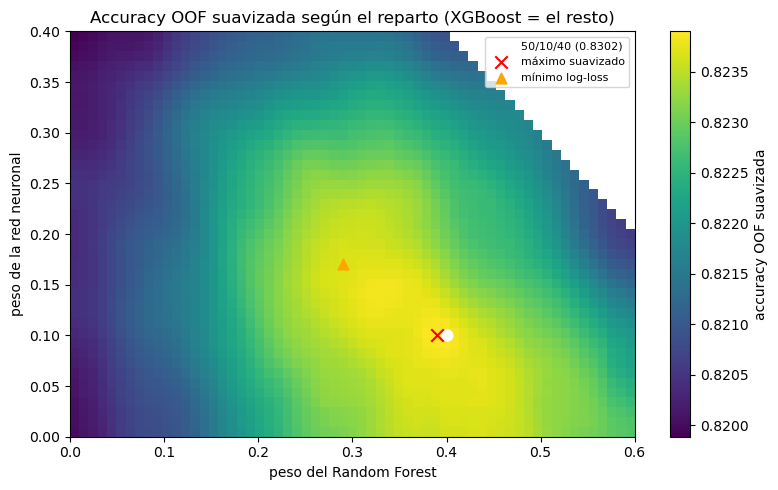

máximo bruto       -> submission_fino_50_10_40.csv | 0 pozos distintos del 0.8302
máximo suavizado   -> submission_fino_51_10_39.csv | 7 pozos distintos del 0.8302
mínimo log-loss    -> submission_fino_54_17_29.csv | 108 pozos distintos del 0.8302


In [37]:
# ============================================================================
# BARRIDO FINO DE PESOS (XGBoost / red / Random Forest) CON SELECCIÓN ROBUSTA
# Como los pesos suman 1, solo hay dos variables libres: el peso de la red (wn) y el del
# Random Forest (wm); XGBoost se queda con el resto. Evaluamos todos los repartos con
# pasos de 0.01 sobre las predicciones OOF guardadas (segundos).
# La zona buena es una meseta plana, así que el máximo exacto es en buena parte ruido.
# Comparamos tres formas de elegir:
#   1) máximo bruto del accuracy (solo como referencia);
#   2) máximo del accuracy SUAVIZADO (media de los repartos vecinos, ±0.02);
#   3) mínimo del log-loss, una medida continua y menos ruidosa que el accuracy.
# Requiere: la celda OOF con muchas semillas (OOF, folds) y la sección 8 (proba_xgb...).
# ============================================================================
import math
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter
from scipy.optimize import minimize
from sklearn.metrics import log_loss

fx, fn, fm = OOF["final"]          # predicciones OOF de los modelos finales (20/20/10 semillas)
PASO = 0.01
wn_vals = np.round(np.arange(0.00, 0.40 + 1e-9, PASO), 2)    # red neuronal
wm_vals = np.round(np.arange(0.00, 0.60 + 1e-9, PASO), 2)    # Random Forest
MIN_XGB = 0.20

# --- 1. Accuracy de cada reparto (NaN donde XGBoost quedaría por debajo del mínimo) ---
acc = np.full((len(wn_vals), len(wm_vals)), np.nan)
for i, wn in enumerate(wn_vals):
    for j, wm in enumerate(wm_vals):
        wx = 1 - wn - wm
        if wx >= MIN_XGB - 1e-9:
            acc[i, j] = ((wx*fx + wn*fn + wm*fm).argmax(1) == y_full).mean()

# --- 2. Accuracy suavizada: media de los repartos vecinos (ventana de ±0.02) ---
valido = ~np.isnan(acc)
num = uniform_filter(np.nan_to_num(acc), size=5, mode="constant")
den = uniform_filter(valido.astype(float), size=5, mode="constant")
acc_suave = np.where(valido, num / np.maximum(den, 1e-12), np.nan)

def pesos_en(i, j):
    wn, wm = wn_vals[i], wm_vals[j]
    return (round(1 - wn - wm, 2), wn, wm)

i_b, j_b = np.unravel_index(np.nanargmax(acc), acc.shape)
i_s, j_s = np.unravel_index(np.nanargmax(acc_suave), acc_suave.shape)

# --- 3. Mínimo del log-loss (optimización continua, sin rejilla) ---
# Los pesos se escriben como softmax de tres números libres para que sean positivos y sumen 1.
def pesos_softmax(theta):
    e = np.exp(theta - theta.max())
    return e / e.sum()

def objetivo(theta):
    w = pesos_softmax(theta)
    return log_loss(y_full, w[0]*fx + w[1]*fn + w[2]*fm)

res = minimize(objetivo, x0=np.log([0.5, 0.1, 0.4]), method="Nelder-Mead",
               options={"xatol": 1e-4, "fatol": 1e-7, "maxiter": 2000})
w_opt = pesos_softmax(res.x)
# Redondeamos la red y el Random Forest a 2 decimales y XGBoost se queda con el resto,
# para que los pesos sumen exactamente 1 (si no, las probabilidades dejan de sumar 1).
wn_ll, wm_ll = round(float(w_opt[1]), 2), round(float(w_opt[2]), 2)
w_ll = (round(1 - wn_ll - wm_ll, 2), wn_ll, wm_ll)

# --- 4. Comparación de los candidatos ---
acierta_ref = (0.50*fx + 0.10*fn + 0.40*fm).argmax(1) == y_full
candidatos = {"referencia 50/10/40": (0.50, 0.10, 0.40),
              "máximo bruto": pesos_en(i_b, j_b),
              "máximo suavizado": pesos_en(i_s, j_s),
              "mínimo log-loss": w_ll}

filas = []
for nombre, (wx, wn, wm) in candidatos.items():
    p = wx*fx + wn*fn + wm*fm
    acierta = p.argmax(1) == y_full
    b = int((acierta & ~acierta_ref).sum()); c = int((~acierta & acierta_ref).sum())
    z = (b - c) / math.sqrt(b + c) if (b + c) else 0.0
    por_trozo = [acierta[va].mean() for _, va in folds]   # accuracy en cada una de las 5 partes
    filas.append({"criterio": nombre, "XGB/red/RF": f"{round(wx*100)}/{round(wn*100)}/{round(wm*100)}",
                  "accuracy OOF": round(acierta.mean(), 4), "log-loss": round(log_loss(y_full, p), 4),
                  "neto vs 50/10/40": b - c, "z": round(z, 2),
                  "peor parte": round(min(por_trozo), 4), "mejor parte": round(max(por_trozo), 4)})
print(pd.DataFrame(filas).to_string(index=False))

# --- 5. Mapa de la accuracy suavizada (la meseta) ---
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(acc_suave, origin="lower", aspect="auto", cmap="viridis",
               extent=[wm_vals[0], wm_vals[-1], wn_vals[0], wn_vals[-1]])
ax.scatter([0.40], [0.10], c="white", marker="o", s=60, label="50/10/40 (0.8302)")
ax.scatter([wm_vals[j_s]], [wn_vals[i_s]], c="red", marker="x", s=80, label="máximo suavizado")
ax.scatter([w_ll[2]], [w_ll[1]], c="orange", marker="^", s=60, label="mínimo log-loss")
ax.set_xlabel("peso del Random Forest"); ax.set_ylabel("peso de la red neuronal")
ax.set_title("Accuracy OOF suavizada según el reparto (XGBoost = el resto)")
fig.colorbar(im, ax=ax, label="accuracy OOF suavizada")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

# --- 6. Ficheros de envío para los candidatos (modelos finales) ---
pred_0_8302 = (0.50*proba_xgb + 0.10*proba_nn + 0.40*proba_mad).argmax(1)
for nombre, (wx, wn, wm) in candidatos.items():
    if nombre.startswith("referencia"):
        continue
    pred = (wx*proba_xgb + wn*proba_nn + wm*proba_mad).argmax(1)
    fichero = f"submission_fino_{round(wx*100)}_{round(wn*100)}_{round(wm*100)}.csv"
    pd.DataFrame({"id": ids_test, "status_group": le_y.inverse_transform(pred)}).to_csv(fichero, index=False)
    print(f"{nombre:18s} -> {fichero} | {(pred != pred_0_8302).sum()} pozos distintos del 0.8302")